# Dimensionality reduction, manifold learning & feature selection on single-cell RNA-seq

A hands-on tutorial on **PBMC** data (peripheral blood mononuclear cells: the white blood cells you get from an ordinary blood draw).

**What you will learn**

| Part | Question | Methods |
|---|---|---|
| Baseline | How well can we recognise cell types using *all* genes? | k-NN, SVM, Random Forest |
| **A** Dimensionality reduction | Can we squeeze ~1,800 genes into 2–50 *new* coordinates without losing the cell types? | PCA, Kernel PCA, MDS, Isomap, SNE, t-SNE, UMAP |
| **B** Feature selection | Can we keep just 10–200 of the *original* genes? Which genes? | Variance, ANOVA F, Mutual Information, Fisher score, Lasso |
| **C** Visualisation | Which method draws the most faithful 2D map of the cell types? | all of the above in 2D |

Every section follows the same rhythm: **explanation → small code cell → plot → "How to read this graph"**.

> **Running it.** `FAST = True` (the default) uses an 800-cell subsample, one CV repeat and fewer settings, so the whole notebook runs in a few minutes. Set `FAST = False` (or run `python run_pipeline.py`) for the full study. All the heavy lifting lives in `src/`; this notebook calls the same functions as `run_pipeline.py`, so numbers match.

In [1]:
# ── Setup ────────────────────────────────────────────────────────────────────
import os, logging, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

from src.config import load_config, set_seed
from src.data import load_dataset, make_scaler
from src.cv import make_splits
from src.reducers import make_reducer, timed
from src.selection import gene_scores, top_k
from src import plots
from src.experiments import (run_data_summary, run_baseline, run_partA, run_partB, run_partC)

FAST = os.environ.get('TUTORIAL_FAST', '1') == '1'   # ← set to False for the full study

cfg = load_config('config.yaml', fast=FAST)            # every setting lives in config.yaml
SEED = cfg['seed']
set_seed(SEED)                                         # reproducible numpy / python randomness
FIG, TAB, DPI = cfg['figures_dir'], cfg['tables_dir'], cfg['dpi']
logging.basicConfig(level=logging.INFO, format='%(asctime)s  %(message)s', datefmt='%H:%M:%S', force=True)
warnings.filterwarnings('ignore')
pd.set_option('display.precision', 3)

def show(name):
    """Display a figure that the pipeline saved to outputs/figures/."""
    display(Image(filename=str(FIG / name)))

print('FAST mode' if FAST else 'FULL mode', '| dataset:', cfg['dataset'])

FAST mode | dataset: pbmc3k_processed


## 1. The data: single-cell RNA-seq of blood cells

**scRNA-seq** measures, for each individual cell, how many RNA molecules of each gene it contains. A gene that a cell is actively using produces many RNA copies, so the table of counts is a snapshot of *what each cell is doing*. Different cell types use different genes: B cells make antibodies (genes like *CD79A*, *MS4A1*), NK cells carry killing machinery (*NKG7*, *GNLY*), monocytes express *LYZ*, and so on.

The data is a matrix **cells × genes**:

* `pbmc3k_processed` has 2,638 cells. We use its 1,838 *highly variable genes* (HVGs).
* Labels (`louvain`) give 8 cell types that the scanpy authors annotated.
* Values are **log-normalised** counts: each cell is rescaled to the same total, then `log(1 + x)` is taken (see §2).

**Analogy.** Think of each cell as a customer and each gene as a product. The matrix records how much of each product each customer bought. We want to group customers by type from their shopping baskets.

> ⚠️ **Label circularity.** The `louvain` labels were produced by clustering *this same data* in a PCA space with a nearest-neighbour graph. Methods that think in "PCA + neighbours" (PCA, UMAP) therefore have a home advantage. Keep this in mind before declaring a winner. Swapping in `pbmc68k_reduced`, whose labels come from lab sorting, is a good test (change `dataset:` in `config.yaml`).

05:30:42  Data: 806 cells × 1826 genes, 8 cell types. Largest class is 34.7× the smallest. This is strongly imbalanced, so macro-averaged metrics (every class weighs the same) are more honest than plain accuracy.


05:30:42    table  → /mnt/D/EJUST/subjects/AML/Task_one_fashion_mnist/outputs/tables/data_summary.csv


05:30:43    figure → /mnt/D/EJUST/subjects/AML/Task_one_fashion_mnist/outputs/figures/data_class_counts.png


X: 806 cells × 1826 genes   (dtype float32)
Cell types: ['CD4 T cells', 'CD14+ Monocytes', 'B cells', 'CD8 T cells', 'NK cells', 'FCGR3A+ Monocytes', 'Dendritic cells', 'Megakaryocytes']
Largest class is 34.7× the smallest. This is strongly imbalanced, so macro-averaged metrics (every class weighs the same) are more honest than plain accuracy.


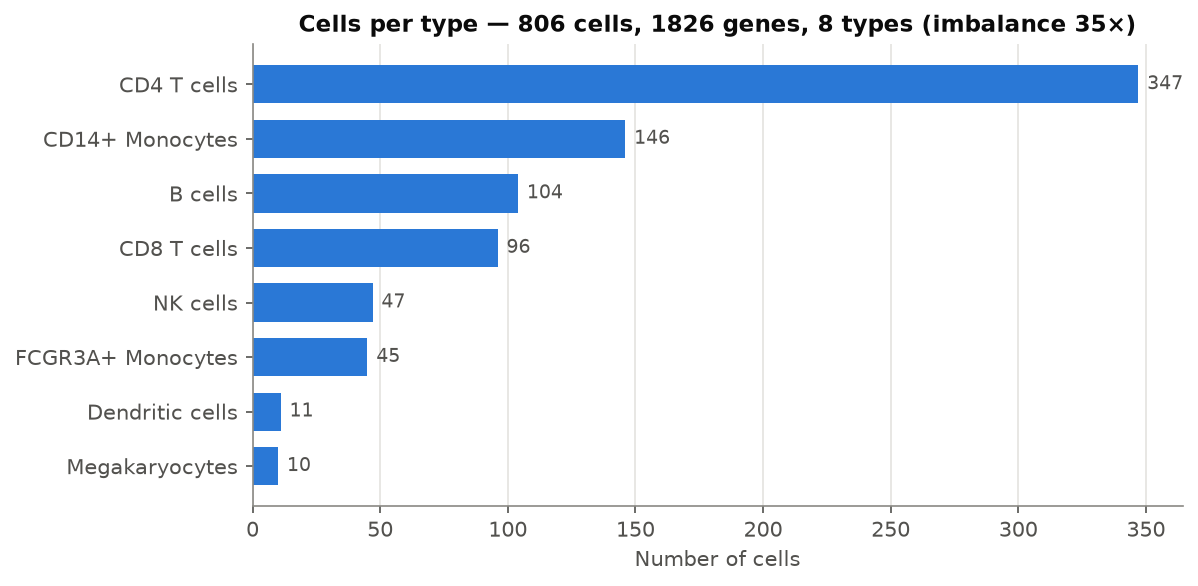

In [2]:
# Load the dataset named in config.yaml (one line to swap datasets).
ds = load_dataset(cfg)
print(f'X: {ds.X.shape[0]} cells × {ds.X.shape[1]} genes   (dtype {ds.X.dtype})')
print('Cell types:', ds.class_names)

# Summary table + bar chart of cells per type (saved to outputs/).
summary = run_data_summary(ds, cfg)
print(summary['note'])
show('data_class_counts.png')

**How to read this graph.** Each bar is one cell type and its length is the number of cells. CD4 T cells dominate, while dendritic cells and megakaryocytes are tiny. That **class imbalance** matters: a lazy model that always answers "CD4 T cell" would already get ~43 % accuracy. We therefore also report **macro**-averaged precision, recall and F1, which give every cell type equal weight, so mistakes on the rare types are not drowned out. We also use **stratified** folds, so every fold keeps these proportions.

## 2. Preprocessing count data (and our first pitfall)

Raw counts are not ready for distance-based methods. The standard recipe, all already applied to `pbmc3k_processed`, is:

1. **Normalise total counts** (`sc.pp.normalize_total`): a cell that happened to be sequenced twice as deeply shows twice the counts for every gene. Rescale every cell to the same total (e.g. 10,000) so we compare *proportions*, not sequencing depth.
2. **log1p** (`sc.pp.log1p`): counts are extremely skewed (a few genes have thousands of copies). `log(1 + x)` compresses the range so a handful of genes do not dominate every distance.
3. **Highly variable genes** (optional, `sc.pp.highly_variable_genes`): keep the ~2,000 genes that vary most between cells. The rest are mostly noise.
4. **Scale** (z-score each gene) and **clip** at ±10: every gene gets mean 0 and variance 1, so each counts equally in distances. Clipping stops a gene expressed in only 3 cells from producing a z-score of 40 that hijacks PCA.

**Leakage note.** Step 4 learns a mean and standard deviation from the data. If it is computed on *all* cells before cross-validation, the test cells leak into training. That's why we start from the **unscaled** log-normalised matrix (`feature_source: lognorm_hvg`) and fit the scaler *inside each training fold*.

**Pitfall demo.** Variance-based selection only makes sense *before* scaling. After z-scoring, every gene has variance 1, so "pick the most variable genes" picks at random:

In [3]:
import scanpy as sc
sc.settings.datasetdir = cfg['root'] / cfg['data_dir']
scaled_X = np.asarray(sc.datasets.pbmc3k_processed().X)       # the pre-scaled matrix scanpy ships

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].hist(ds.X.var(axis=0), bins=60, color=plots.CAT[0])
axes[0].set(title='Log-normalised (what we use)', xlabel='Gene variance', ylabel='Number of genes')
axes[1].hist(scaled_X.var(axis=0), bins=60, color=plots.CAT[1])
axes[1].set(title='After z-scoring (scanpy .X)', xlabel='Gene variance')
fig.suptitle('Gene variances before vs after scaling', fontweight='bold')
fig.tight_layout(); fig.savefig(FIG / 'prep_gene_variance.png', dpi=DPI); plt.show()

**How to read this graph.** Left: in log-normalised data, gene variances spread over a wide range, and a few genes are much more variable than the rest. Those are the informative ones Variance Threshold will keep. Right: after z-scoring, almost every gene sits at variance ≈ 1. A small tail falls below 1 because scanpy clipped extreme values. Ranking genes by variance here would be meaningless. **Order of operations matters.**

## 3. How we evaluate: protocol, metrics and timing

**Stratified k-fold cross-validation, repeated.** Split the cells into 5 folds with the same cell-type mix. Train on 4 folds, test on the 5th, and rotate. Repeat with different shuffles (3 × 5 = 15 train/test splits in full mode). **Every method sees exactly the same splits**, so we can compare methods fold by fold (paired tests).

**Metrics** (all on the held-out fold):

| Metric | Plain meaning |
|---|---|
| Accuracy | Fraction of cells labelled correctly. Inflated by big classes. |
| Macro precision | For each type: "when I say *B cell*, how often am I right?", averaged over types. |
| Macro recall | For each type: "of the real B cells, how many did I find?", averaged. |
| Macro F1 | Harmonic mean of precision and recall, averaged over types. **Our main imbalance-aware score.** |
| Cohen's κ | Accuracy corrected for agreement expected by chance (0 = chance, 1 = perfect). |
| One-vs-rest ROC AUC | For each type, how well the predicted probabilities rank its cells above the others (0.5 = random, 1 = perfect), averaged. |

**Two clocks.** `time.process_time()` measures **CPU time**: how much processor work this program did, summed over all its threads. `time.perf_counter()` measures **wall time**: what your watch shows. With multithreaded code (Random Forest, UMAP, NumPy), CPU time can be *larger* than wall time. CPU time is the fairer measure of "how much computation does this method cost". Wall time is what you wait.

## 4. Baseline: all genes, no reduction

Three classifiers, each with a different idea of "similar":

* **k-NN (k = 7, distance-weighted)**: "you are what your 7 nearest neighbours are", with closer neighbours getting a bigger vote. *Analogy: ask your 7 closest neighbours which party they vote for.* It has no training step but suffers when there are many dimensions (see below).
* **SVM (RBF kernel, C = 10, γ = 'scale')**: finds smooth, curved boundaries with the widest possible safety margin between types. *Analogy: drawing borders on a map that stay as far as possible from every town.* Here `probability=True` so we can compute ROC AUC; this adds an internal cross-validation and costs CPU.
* **Random Forest (100 trees)**: many decision trees, each asking yes/no questions like "is CD79A > 1.2?", and they vote. *Analogy: a committee of 100 slightly different flowcharts.* Robust, handles irrelevant genes well because each split picks a useful gene.

In [4]:
# The SAME stratified folds are reused by every experiment below.
splits = make_splits(ds.y, cfg)
print(f"{len(splits)} train/test splits ({cfg['cv']['repeats']} repeats × {cfg['cv']['folds']} folds)")

# Scaler + classifier are fit on each training fold only; results → outputs/tables/baseline_*.csv
base = run_baseline(ds, cfg, splits)
base['summary'][['classifier', 'accuracy_mean', 'accuracy_std', 'macro_f1_mean', 'kappa_mean',
                 'auc_roc_mean', 'train_cpu_mean', 'pred_cpu_mean', 'total_wall_mean']]

05:30:43  Baseline: 5 folds × 3 classifiers on 1826 genes


5 train/test splits (1 repeats × 5 folds)


05:30:45    repeat 0 fold 0 done


05:30:47    repeat 0 fold 1 done


05:30:49    repeat 0 fold 2 done


...

05:30:53    repeat 0 fold 4 done


05:30:53    table  → /mnt/D/EJUST/subjects/AML/Task_one_fashion_mnist/outputs/tables/baseline_results_folds.csv


05:30:53    table  → /mnt/D/EJUST/subjects/AML/Task_one_fashion_mnist/outputs/tables/baseline_summary.csv


05:30:53    figure → (PosixPath('/mnt/D/EJUST/subjects/AML/Task_one_fashion_mnist/outputs/figures/baseline_accuracy_f1.png'), PosixPath('/mnt/D/EJUST/subjects/AML/Task_one_fashion_mnist/outputs/figures/baseline_cpu_time.png'))


,classifier,accuracy_mean,accuracy_std,macro_f1_mean,kappa_mean,auc_roc_mean,train_cpu_mean,pred_cpu_mean,total_wall_mean
0,kNN,0.561,0.093,0.274,0.341,0.726,9.768e-04,0.053,0.035
1,SVM,0.852,0.010,0.643,0.792,0.987,1.661e+00,0.183,1.819
2,RF,0.919,0.012,0.783,0.890,0.994,2.744e-01,0.034,0.176


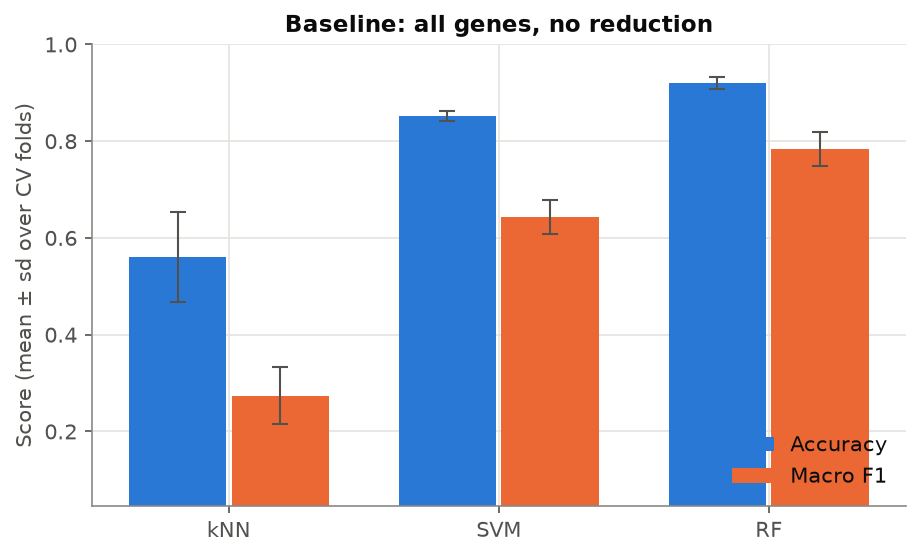

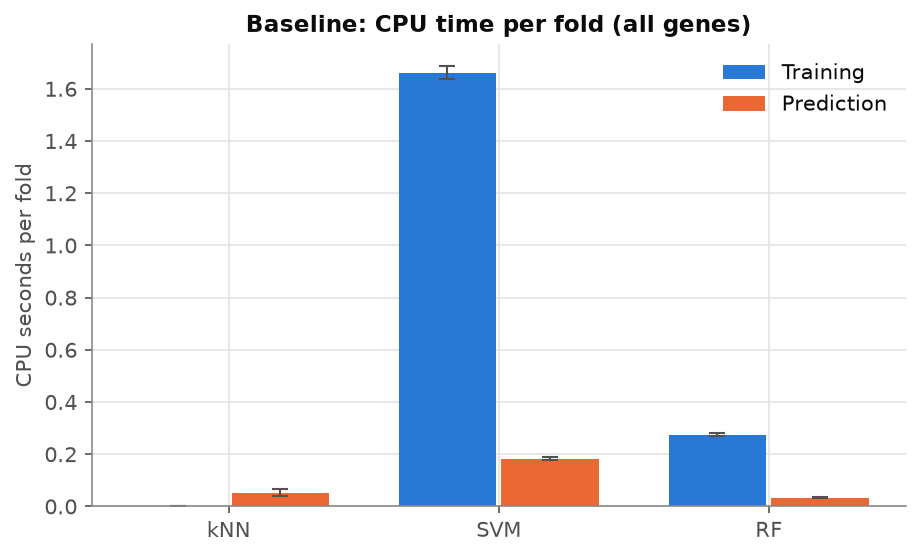

In [5]:
show('baseline_accuracy_f1.png')
show('baseline_cpu_time.png')

**How to read these graphs.** Top: bar height is the mean score over folds, and the whisker is ± one standard deviation. A long whisker means results depend on which cells landed in the test fold. Compare accuracy (blue) with macro-F1 (orange) for each classifier. A large gap means the classifier does well on big types but stumbles on rare ones. Bottom: CPU seconds per fold for training and for prediction.

**Why is k-NN so bad here?** With ~1,800 scaled genes, most of them noise for any given cell type, all pairwise distances become similar (**curse of dimensionality**). The "nearest" neighbours are barely nearer than random cells. Random Forest is immune because it *chooses* genes. This is the strongest motivation for Parts A and B: remove the noise dimensions and distances become meaningful again.

## 5. Part A: dimensionality reduction

**Dimensionality reduction (DR)** builds a small number of *new* coordinates, each a mix of many genes, that keep the important structure.

* **Linear vs nonlinear.** Linear methods (PCA) can only rotate and project, like shining a torch to cast a shadow. Nonlinear methods can "unroll" curved structure.
* **Manifold.** The idea that data living in 1,800 dimensions really lies near a much lower-dimensional curved surface. For example, a differentiation trajectory is a 1D curve through gene space. Manifold learning tries to find that surface.
* **Global vs local structure.** Some methods keep *large* distances (how far apart are T cells and monocytes?). Others only keep *small* neighbourhoods (who is next to whom?). No 2D picture can keep both perfectly.

### Two design choices you must understand

**1. PCA pre-step to 50 dims.** For t-SNE, SNE, MDS, Isomap and UMAP we first project the scaled data onto its top 50 principal components. This (a) throws away the low-variance directions, which are mostly technical noise, and (b) makes O(n²) distance computations ~36× cheaper (50 instead of 1,838 numbers per cell). It is the standard practice in scanpy and Seurat. Methods asked for exactly 50 output dims then just re-arrange the 50 PCs.

**2. Inductive vs transductive (data leakage).**
* **Inductive** methods (PCA, Kernel PCA, Isomap, UMAP) learn a *function* from gene space to the embedding. We `fit` on the training fold and `transform` the test fold, so test cells never influence the map. ✅ No leakage.
* **Transductive** methods (t-SNE, SNE, MDS) only produce coordinates for the points they were given. There is no `transform()` for new cells. So we embed **train + test together** and then train the classifier on the training rows. The labels never leak, but the *test cells shaped the embedding*. Their positions were optimised together with the training cells, which slightly flatters these methods. They are marked **(T)** and drawn dashed in every plot. Read their accuracies as "how separable is the data in this embedding", not "how well would this pipeline work on tomorrow's cells".

> Since every fold's train + test equals all cells, the transductive embedding is identical across the 5 folds of a repeat. We compute it once per repeat (5× cheaper, same result).

In the method sections below, each small cell fits a 2D embedding of **all cells** for illustration (and caches it for Part C). The leakage-safe benchmark runs afterwards in §5.8.

In [6]:
EMB2D = {}                                    # method → (Z, cpu_s, wall_s), reused in Part C
Xs = make_scaler(cfg).fit_transform(ds.X)     # scaled + clipped genes (illustration only)
n, p = ds.X.shape

def fit_2d(method, **override):
    """Build the reducer pipeline (scale → [PCA-50] → method), fit it on all cells, time it."""
    local = {**cfg, 'hyper': {**cfg['hyper'], **override}}
    red = make_reducer(method, 2, local, SEED, n, p)
    Z, cpu, wall = timed(red.fit_transform, ds.X)
    return Z, cpu, wall, red

def one_panel(ax, Z, title, caption=''):
    plots.scatter_ax(ax, Z, ds.y, ds.class_names, title, caption)

def add_legend(fig):
    fig.legend(handles=plots.legend_handles(ds.class_names), loc='lower center',
               ncol=4, bbox_to_anchor=(0.5, -0.12), fontsize=8)

### 5.1 PCA (Principal Component Analysis)

* **Preserves:** global structure and variance. Large distances are kept as well as any linear projection can.
* **How it works:** find the direction in gene space along which cells vary most (PC1), then the next one at right angles (PC2), and so on. Mathematically, these are the top eigenvectors of the covariance matrix: $\;\Sigma = \tfrac{1}{n} X^\top X,\; \Sigma v_k = \lambda_k v_k$. The embedding is $Z = X V_{1:d}$, and $\lambda_k$ is the variance explained by PC $k$.
* **Key hyperparameter:** the number of components.
* **Strengths:** fast, deterministic, has `transform()`, components are interpretable (gene loadings), and denoises well.
* **Weaknesses:** linear only. Curved structures get squashed, and a few very variable genes can dominate.
* **Analogy:** photographing a 3D sculpture from the angle that shows the most detail. You lose depth, but you choose the most informative view.

In [7]:
from sklearn.decomposition import PCA
pca50 = PCA(n_components=50, random_state=SEED).fit(Xs)       # how much variance does each PC carry?
Z, cpu, wall, _ = fit_2d('PCA'); EMB2D['PCA'] = (Z, cpu, wall)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
evr = pca50.explained_variance_ratio_ * 100
axes[0].bar(np.arange(1, 51), evr, color=plots.CAT[0])
axes[0].set(xlabel='Principal component', ylabel='% of total variance explained', title='Scree plot')
for k in (2, 10, 50):
    axes[0].annotate(f'first {k}: {evr[:k].sum():.0f}%', xy=(k, evr[k - 1]), xytext=(k + 3, evr[0] * (0.9 - k / 120)),
                     fontsize=9, color=plots.INK2, arrowprops=dict(arrowstyle='-', color=plots.MUTED))
one_panel(axes[1], Z, 'PCA — 2D', f'CPU {cpu:.2f}s')
add_legend(fig); fig.tight_layout(); fig.savefig(FIG / 'partA_pca_scree.png', dpi=DPI, bbox_inches='tight'); plt.show()

**How to read this graph.** Left (scree plot): each bar is the share of total variance captured by one principal component. Look for the "elbow" where bars flatten: after it, components mostly carry noise. With scRNA-seq the total explained by 50 PCs looks small (~20–30 %), because most of the variance is per-gene noise. That is exactly what we want to throw away. Right: cells projected on PC1 vs PC2, with numbers marking the median of each type. PCA separates the big families (lymphocytes vs monocytes), but types within a family overlap. Two linear directions are simply not enough for 8 types.

### 5.2 Kernel PCA (RBF kernel)

* **Preserves:** nonlinear structure, as measured by a similarity kernel.
* **How it works:** instead of the covariance of genes, compute a similarity between every pair of cells, $k(x_i,x_j) = \exp(-\gamma\lVert x_i - x_j\rVert^2)$, and run PCA on that $n\times n$ kernel matrix. Implicitly, PCA happens in a huge feature space where curved patterns become straight (the "kernel trick").
* **Key hyperparameter:** γ, the kernel width. Large γ means only very close cells look similar (very local). Small γ behaves almost like plain PCA. The default `gamma: null` uses 1 / n_genes.
* **Strengths:** can capture curved structure, and has `transform()`.
* **Weaknesses:** O(n²) memory, very sensitive to γ, and the axes are hard to interpret.
* **Analogy:** a crumpled sheet of paper. Kernel PCA looks at the sheet through special glasses (the kernel) that make the crumples look flat, then applies ordinary PCA.

In [8]:
# Hyperparameter sensitivity: the same data with three kernel widths γ.
gammas = [1 / (10 * p), 1 / p, 10 / p]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
for ax, g in zip(axes, gammas):
    Z, cpu, wall, _ = fit_2d('Kernel PCA', kpca_gamma=g)
    one_panel(ax, Z, f'Kernel PCA, γ = {g:.1e}', f'CPU {cpu:.2f}s')
    if g == gammas[1]:
        EMB2D['Kernel PCA'] = (Z, cpu, wall)                     # the default γ = 1/n_genes
add_legend(fig); fig.tight_layout(); fig.savefig(FIG / 'partA_kpca_gamma.png', dpi=DPI, bbox_inches='tight'); plt.show()

**How to read this graph.** Same cells, three values of γ. Small γ (left) behaves almost like PCA. Large γ (right) makes every cell dissimilar to all but its closest neighbours, so the embedding collapses into a few spikes or a single blob. Kernel PCA is only as good as its γ, and there is no universal default. In practice you tune γ by cross-validation.

### 5.3 MDS (metric Multidimensional Scaling)

* **Preserves:** all pairwise distances (global structure).
* **How it works:** place points in 2D so that their distances match the original distances as well as possible, by minimising the *stress* $\;\sum_{i<j}\big(d_{ij} - \lVert z_i - z_j\rVert\big)^2$ with the SMACOF algorithm. We initialise with classical MDS, which equals PCA on the distance matrix, then refine.
* **Key hyperparameters:** `max_iter`, `n_init` (restarts).
* **Strengths:** a clear objective, faithful to large-scale geometry.
* **Weaknesses:** O(n²) time and memory, **no `transform()`** (transductive), and big distances dominate the stress, so local neighbourhoods get blurred.
* **Analogy:** given a table of driving distances between cities, draw a map. MDS gets the country shape right but may misplace two neighbouring villages.

In [9]:
from scipy.spatial.distance import pdist
Z, cpu, wall, red = fit_2d('MDS'); EMB2D['MDS'] = (Z, cpu, wall)

# Shepard diagram: original (PCA-50) distance vs 2D distance for a random subset of cell pairs.
rng = np.random.default_rng(SEED)
idx = rng.choice(n, min(400, n), replace=False)
X50 = red[:-1].transform(ds.X)                 # the scale → PCA-50 part of the pipeline
d_hi, d_lo = pdist(X50[idx]), pdist(Z[idx])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
axes[0].scatter(d_hi, d_lo, s=2, alpha=0.25, color=plots.CAT[0])
axes[0].set(xlabel='Distance in PCA-50 space', ylabel='Distance in 2D MDS map',
            title=f'Shepard diagram (Spearman ρ = {pd.Series(d_hi).corr(pd.Series(d_lo), method="spearman"):.2f})')
one_panel(axes[1], Z, 'MDS (T) — 2D', f'CPU {cpu:.1f}s')
add_legend(fig); fig.tight_layout(); fig.savefig(FIG / 'partA_mds_shepard.png', dpi=DPI, bbox_inches='tight'); plt.show()

**How to read this graph.** Left: each dot is a pair of cells. If MDS were perfect, all dots would lie on a straight rising line. Large distances are reproduced reasonably well (the cloud rises), but small original distances are scattered, so neighbours are not guaranteed to stay neighbours. This is the global-vs-local trade-off in one picture. Right: the MDS map. Notice how much it resembles PCA. Both preserve global distances.

### 5.4 Isomap

* **Preserves:** *geodesic* distances, meaning distances measured along the data manifold rather than straight through space.
* **How it works:** (1) connect each cell to its *k* nearest neighbours, giving a graph; (2) compute shortest-path distances through the graph (like walking along roads instead of flying); (3) run classical MDS on those path distances.
* **Key hyperparameter:** `n_neighbors`. Too small and the graph falls apart into islands. Too large and it takes shortcuts across gaps, which makes it behave like PCA.
* **Strengths:** unrolls curved manifolds (the classic "Swiss roll"), and has `transform()`.
* **Weaknesses:** sensitive to noise and shortcut edges, and it assumes one connected manifold. Separate cell types are separate islands, not one curve.
* **Analogy:** measuring distance between two cities by road (geodesic) rather than as the crow flies. Two towns on opposite sides of a mountain are far apart by road.

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
for ax, k in zip(axes, [5, cfg['hyper']['isomap_neighbors'], 50]):
    Z, cpu, wall, _ = fit_2d('Isomap', isomap_neighbors=k)
    one_panel(ax, Z, f'Isomap, n_neighbors = {k}', f'CPU {cpu:.1f}s')
    if k == cfg['hyper']['isomap_neighbors']:
        EMB2D['Isomap'] = (Z, cpu, wall)
add_legend(fig); fig.tight_layout(); fig.savefig(FIG / 'partA_isomap_neighbors.png', dpi=DPI, bbox_inches='tight'); plt.show()

**How to read this graph.** With few neighbours (left) the graph is fragmented, and Isomap stretches the pieces into long arms. With many neighbours (right) shortcuts appear and the picture drifts towards PCA. Isomap tends to draw cell types as *rays* from a centre: it is trying to represent separate clusters as one continuous road network.

### 5.5 SNE (Stochastic Neighbour Embedding), our own implementation

* **Preserves:** local neighbourhoods, in a probabilistic sense.
* **How it works:** turn distances into "neighbour probabilities". In the original space, $p_{j|i} \propto \exp(-\lVert x_i - x_j\rVert^2 / 2\sigma_i^2)$, where each $\sigma_i$ is tuned so cell *i* has about *perplexity* effective neighbours. Do the same in 2D with $q_{ij} \propto \exp(-\lVert z_i - z_j\rVert^2)$, then move the 2D points by gradient descent to minimise the KL divergence $\mathrm{KL}(P\Vert Q) = \sum p_{ij}\log\frac{p_{ij}}{q_{ij}}$. See `src/sne.py`: a short, readable implementation.
* **Key hyperparameters:** perplexity (~5–50), number of iterations, learning rate.
* **Strengths:** a very good local neighbourhood structure, and the clearest way to understand t-SNE.
* **Weaknesses:** the **crowding problem**: a 2D Gaussian has too little room far from the centre, so moderately distant points get squashed together. Also O(n²) per iteration, and no `transform()` (transductive).
* **Analogy:** each cell writes down a list of its closest friends with confidence scores. SNE seats everyone at a table so that each person's list of nearest table-mates matches their friend list.

In [11]:
Z, cpu, wall, red = fit_2d('SNE'); EMB2D['SNE'] = (Z, cpu, wall)
loss = red.named_steps['reduce'].model_.loss_curve_       # KL divergence logged every 10 iterations

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
axes[0].plot(np.arange(len(loss)) * 10, loss, color=plots.CAT[0])
axes[0].set(xlabel='Iteration', ylabel='KL(P || Q)', title='SNE optimisation: loss going down')
one_panel(axes[1], Z, 'SNE (T) — 2D', f'CPU {cpu:.1f}s')
add_legend(fig); fig.tight_layout(); fig.savefig(FIG / 'partA_sne_loss.png', dpi=DPI, bbox_inches='tight'); plt.show()

**How to read this graph.** Left: the KL divergence (lower is better) drops quickly and then flattens, so the optimiser has converged. If it were still falling steeply at the end, you would increase the number of iterations. Right: the SNE map. Clusters are visible but sit close together with fuzzy borders: that is the crowding problem. Compare it with t-SNE next.

### 5.6 t-SNE (t-distributed SNE)

* **Preserves:** local neighbourhoods.
* **How it works:** exactly like SNE, but the 2D similarities use a heavy-tailed **Student-t** distribution: $q_{ij} \propto (1 + \lVert z_i - z_j\rVert^2)^{-1}$. Heavy tails give moderately distant points plenty of room, which fixes the crowding problem and produces well-separated clusters. sklearn uses the Barnes–Hut approximation (fast, but **only ≤ 3 output dims**). For more dims we must use `method='exact'` (O(n²), slow) or skip. That is what `tsne_high_dim` in the config controls.
* **Key hyperparameters:** **perplexity** (effective neighbourhood size), iterations, learning rate, early exaggeration.
* **Strengths:** beautiful, well-separated clusters; the standard for visualising scRNA-seq for years.
* **Weaknesses:** **distances between clusters and cluster sizes are not meaningful**. Results are sensitive to perplexity and random seed, there is no `transform()` (transductive), and it is slow for large n.
* **Analogy:** SNE with extra elbow room. Friends still sit together, but tables can now be pushed far apart. Don't read anything into *how* far.

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
for ax, perp in zip(axes, [5, cfg['hyper']['tsne_perplexity'], 100]):
    Z, cpu, wall, red = fit_2d('t-SNE', tsne_perplexity=perp)
    kl = red.named_steps['reduce'].kl_divergence_
    one_panel(ax, Z, f't-SNE (T), perplexity = {perp}', f'CPU {cpu:.1f}s · final KL {kl:.2f}')
    if perp == cfg['hyper']['tsne_perplexity']:
        EMB2D['t-SNE'] = (Z, cpu, wall)
add_legend(fig); fig.tight_layout(); fig.savefig(FIG / 'partA_tsne_perplexity.png', dpi=DPI, bbox_inches='tight'); plt.show()

**How to read this graph.** Same data, three perplexities. Low perplexity (5) looks only at very close neighbours: clusters shatter into small islands that are *not* real sub-types. High perplexity (100) considers more neighbours, so clusters are rounder and some global arrangement emerges. **The gaps between clusters and their sizes change with perplexity.** That's why you must never read biological meaning into t-SNE distances. Compare the final KL values only *within* one perplexity, never across.

### 5.7 UMAP (Uniform Manifold Approximation and Projection)

* **Preserves:** local neighbourhoods, with somewhat more global structure than t-SNE.
* **How it works:** (1) build a weighted k-nearest-neighbour graph in the original space, treated as a "fuzzy" topological description of the manifold; (2) lay out a 2D graph whose fuzzy structure matches it, by minimising a cross-entropy with stochastic gradient descent (attract neighbours, repel random non-neighbours).
* **Key hyperparameters:** `n_neighbors` (local vs global view: 5 = very local, 50+ = more global) and `min_dist` (how tightly points may pack: small = dense clumps, large = even spread).
* **Strengths:** fast and scalable, **has `transform()`** for new cells, keeps more global structure than t-SNE, works for >3 output dims, and is the current default in scanpy and Seurat.
* **Weaknesses:** still distorts distances and densities, and is sensitive to hyperparameters and seed. It is stochastic; we fix `random_state`, which also disables parallelism.
* **Analogy:** a rubber-band model. Every cell is tied to its nearest friends with rubber bands and pushed away from strangers, then the whole thing settles on a table.

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(11, 9.4))
for ax, (nn, md_) in zip(axes.ravel(), [(5, 0.1), (cfg['hyper']['umap_neighbors'], 0.1), (50, 0.1), (cfg['hyper']['umap_neighbors'], 0.8)]):
    Z, cpu, wall, _ = fit_2d('UMAP', umap_neighbors=nn, umap_min_dist=md_)
    one_panel(ax, Z, f'UMAP, n_neighbors={nn}, min_dist={md_}', f'CPU {cpu:.1f}s')
    if (nn, md_) == (cfg['hyper']['umap_neighbors'], cfg['hyper']['umap_min_dist']) and 'UMAP' not in EMB2D:
        EMB2D['UMAP'] = (Z, cpu, wall)
add_legend(fig); fig.tight_layout(); fig.savefig(FIG / 'partA_umap_params.png', dpi=DPI, bbox_inches='tight'); plt.show()

**How to read this graph.** Top-left vs bottom-left: increasing `n_neighbors` from 5 to 50 trades fine local detail for a more connected global layout (small islands merge, and related types such as CD4 and CD8 T cells move together). Top-right vs bottom-right: `min_dist = 0.8` spreads every cluster out evenly, which hides density differences that `min_dist = 0.1` shows. (The first UMAP call also includes numba's one-time compilation, so its CPU time is inflated.)

### 5.8 The leakage-safe benchmark: does reduction help classification?

Now the real experiment. For every method × target dimension (2, 5, 10, 20, 50), on the same CV folds:

1. Inductive methods: fit scaler → [PCA-50] → reducer on the **training fold**, then `transform` the test fold. Transductive methods: embed train + test together (marked **(T)**).
2. Train k-NN, SVM and RF on the reduced coordinates.
3. Record all metrics plus CPU time for reducer fit, reducer transform, classifier train and predict.
4. On the first fold's test cells, measure **embedding quality** against the original scaled gene space:
   * **Trustworthiness** (0–1): are the embedding's neighbours *real* neighbours? It penalises false neighbours, i.e. points brought close together that were far apart.
   * **Continuity** (0–1): are real neighbours *kept*? It is the same formula with the two spaces swapped, and penalises neighbours that were torn apart.
   * **k-NN preservation**: the fraction of each cell's 10 nearest neighbours that are still among its 10 nearest after reduction.
   * **ARI** (adjusted Rand index): run k-means with k = number of cell types on the embedding and compare the clusters with the true labels (0 = random, 1 = identical).
   * **Silhouette**: how well the true cell types form compact, separated groups in the embedding (−1 to 1).

Methods/dimensions that cannot run (e.g. Barnes–Hut t-SNE above 3 dims in fast mode) are skipped with a logged reason and listed in `partA_skipped_or_failed.csv`.

In [14]:
A = run_partA(ds, cfg, base, splits)        # ← the slow cell (a few minutes in FAST mode)
cols = ['method', 'dim', 'classifier', 'transductive', 'accuracy', 'macro_f1', 'delta_accuracy',
        'delta_macro_f1', 'reducer_cpu', 'total_cpu', 'speedup_cpu']
A['summary'][cols].sort_values(['classifier', 'accuracy'], ascending=[True, False]).head(15)

05:31:23  Part A: PCA → 2 dims (inductive)


05:31:25    done in 1.7s


05:31:25  Part A: PCA → 10 dims (inductive)


05:31:26    done in 1.5s


05:31:26  Part A: Kernel PCA → 2 dims (inductive)


...

05:32:13    figure → /mnt/D/EJUST/subjects/AML/Task_one_fashion_mnist/outputs/figures/partA_f1_vs_dim.png


05:32:13    figure → /mnt/D/EJUST/subjects/AML/Task_one_fashion_mnist/outputs/figures/partA_cpu_time.png


05:32:14    figure → /mnt/D/EJUST/subjects/AML/Task_one_fashion_mnist/outputs/figures/partA_delta_accuracy_heatmap.png


05:32:14    figure → /mnt/D/EJUST/subjects/AML/Task_one_fashion_mnist/outputs/figures/partA_quality_vs_dim.png


,method,dim,classifier,transductive,accuracy,macro_f1,delta_accuracy,delta_macro_f1,reducer_cpu,total_cpu,speedup_cpu
5,PCA,10,RF,False,0.916,0.860,-0.004,0.077,0.314,0.651,0.485
26,MDS,10,RF,True,0.912,0.840,-0.007,0.057,12.934,13.150,0.024
14,SNE,2,RF,True,0.908,0.827,-0.011,0.043,9.766,9.966,0.032
20,t-SNE,2,RF,True,0.899,0.802,-0.020,0.018,5.813,5.983,0.053
17,SNE,10,RF,True,0.891,0.778,-0.029,-0.005,24.409,24.631,0.013
38,UMAP,10,RF,False,0.868,0.696,-0.051,-0.087,5.026,5.237,0.060
11,Kernel PCA,10,RF,False,0.857,0.646,-0.062,-0.137,0.430,0.716,0.441
32,Isomap,10,RF,False,0.855,0.666,-0.065,-0.117,3.237,3.525,0.090
23,MDS,2,RF,True,0.830,0.743,-0.089,-0.040,11.736,11.936,0.026
35,UMAP,2,RF,False,0.815,0.671,-0.104,-0.113,5.152,5.321,0.059


In [15]:
A['issues']        # what was skipped and why

,method,dim,status,reason
0,t-SNE,10,skipped,t-SNE: Barnes-Hut supports ≤3 dims; dim=10 ski...


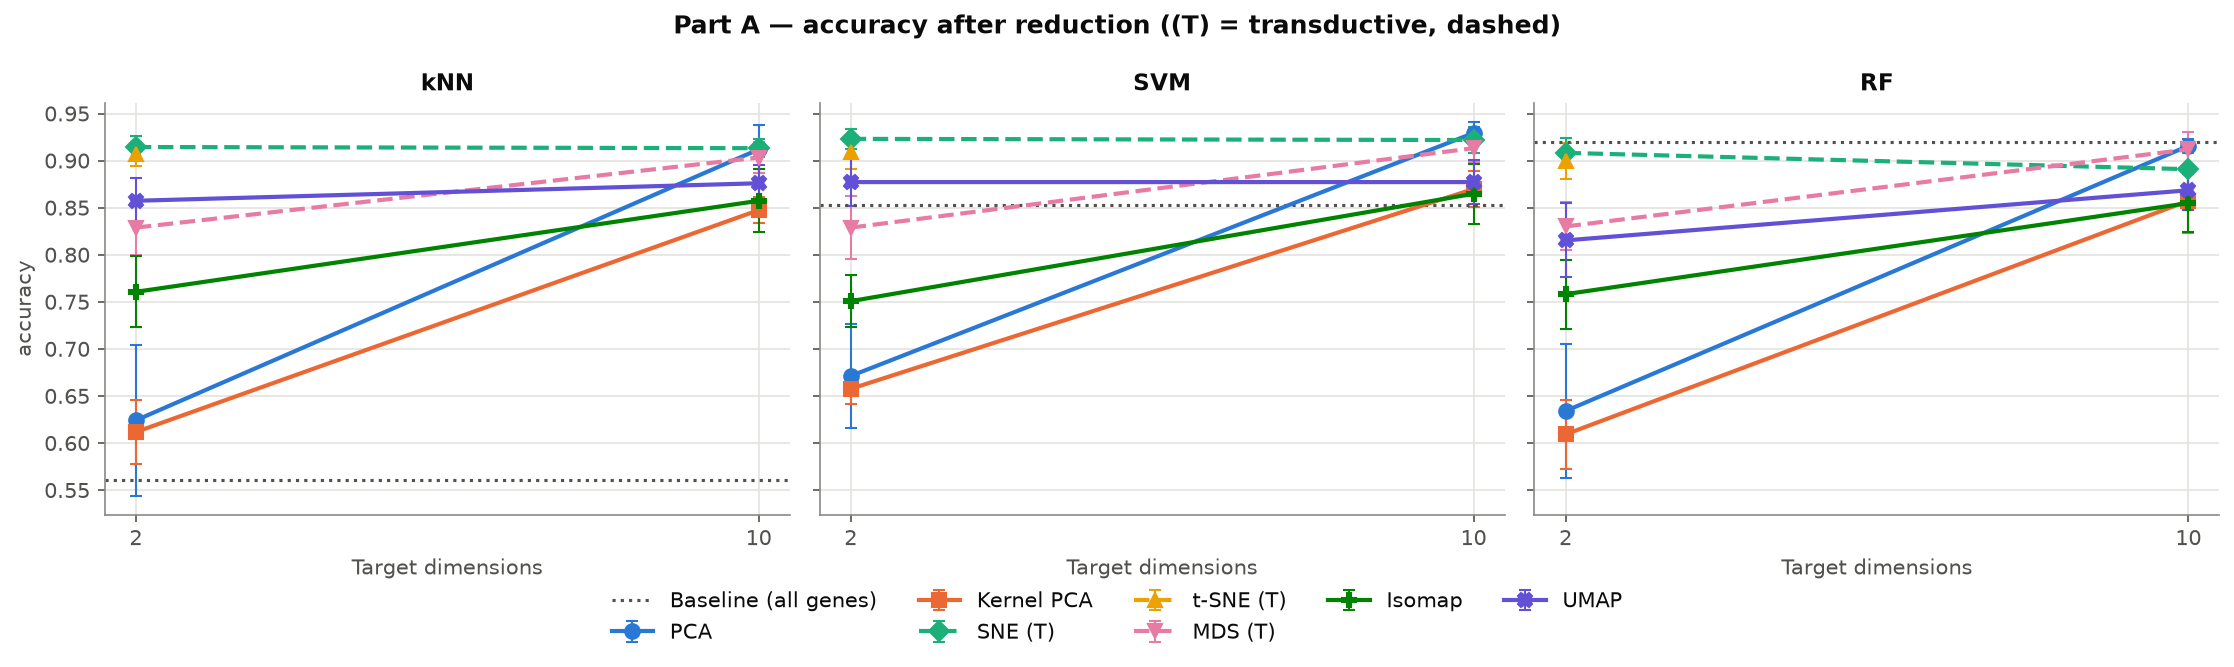

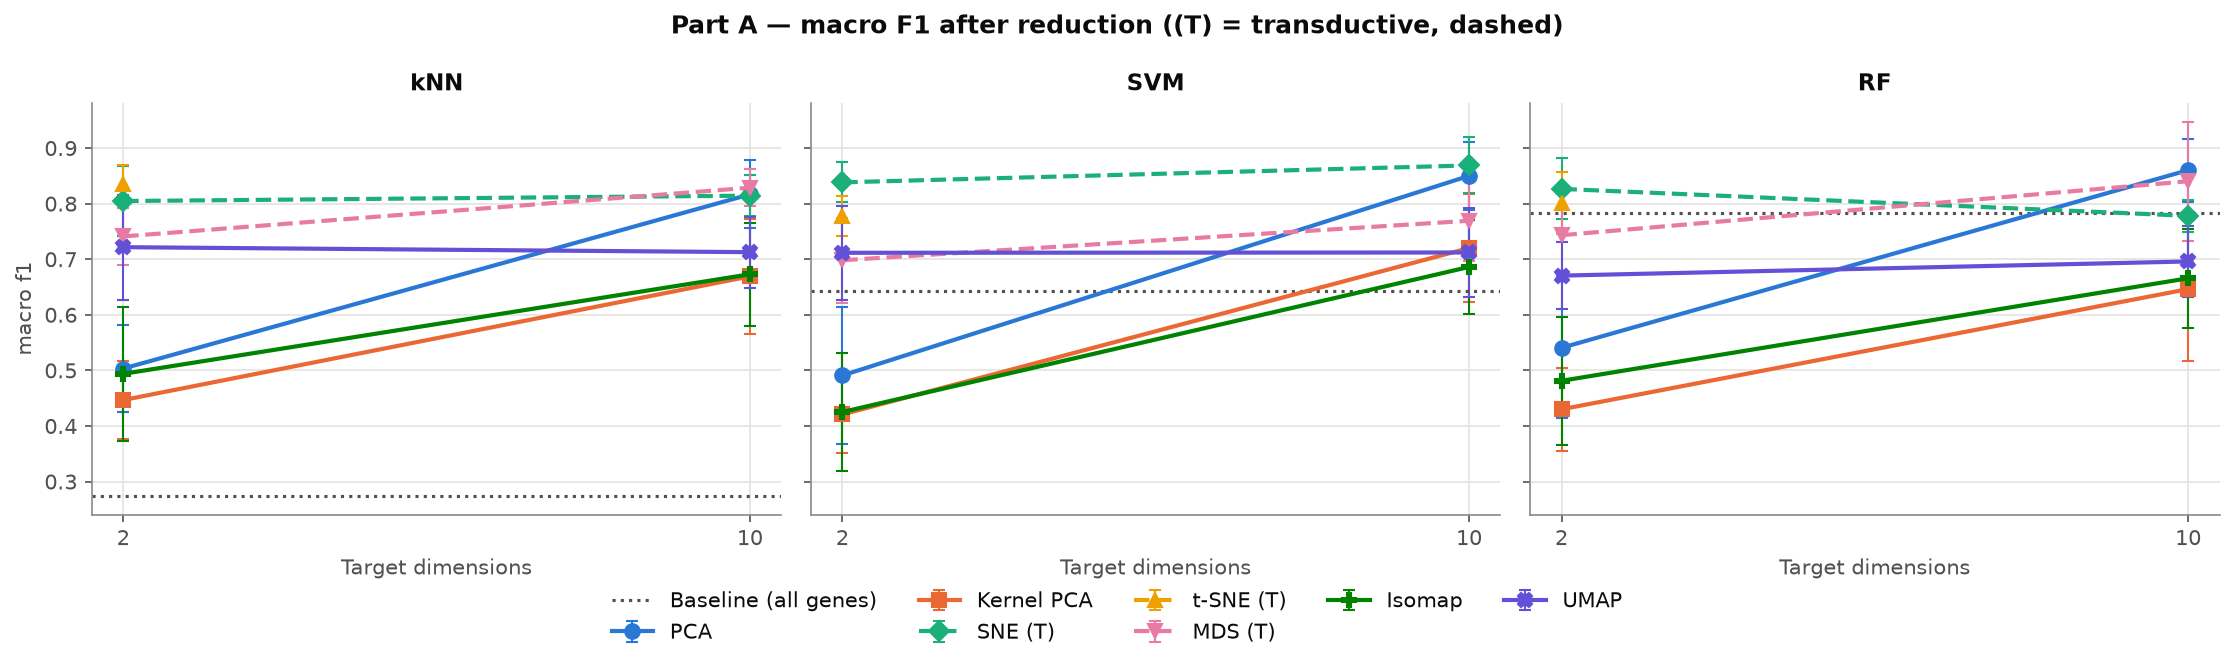

In [16]:
show('partA_accuracy_vs_dim.png')
show('partA_f1_vs_dim.png')

**How to read these graphs.** One panel per classifier. The x-axis is the number of output dimensions (log scale) and the y-axis is mean accuracy (or macro-F1) over CV folds, with ± sd whiskers. The dotted grey line is the all-gene baseline for that classifier. Points **above** the line mean the reduction *helped*. Dashed lines marked (T) are transductive: their test cells helped shape the embedding.

Typical pattern: k-NN jumps far above its baseline once distances are computed in a denoised space. SVM gains a little. Random Forest rarely gains, because it already ignores irrelevant genes, but 10–50 dimensions usually match it. In 2D, the neighbourhood methods (t-SNE, UMAP, SNE) beat PCA by a wide margin, because two linear axes cannot separate 8 types.

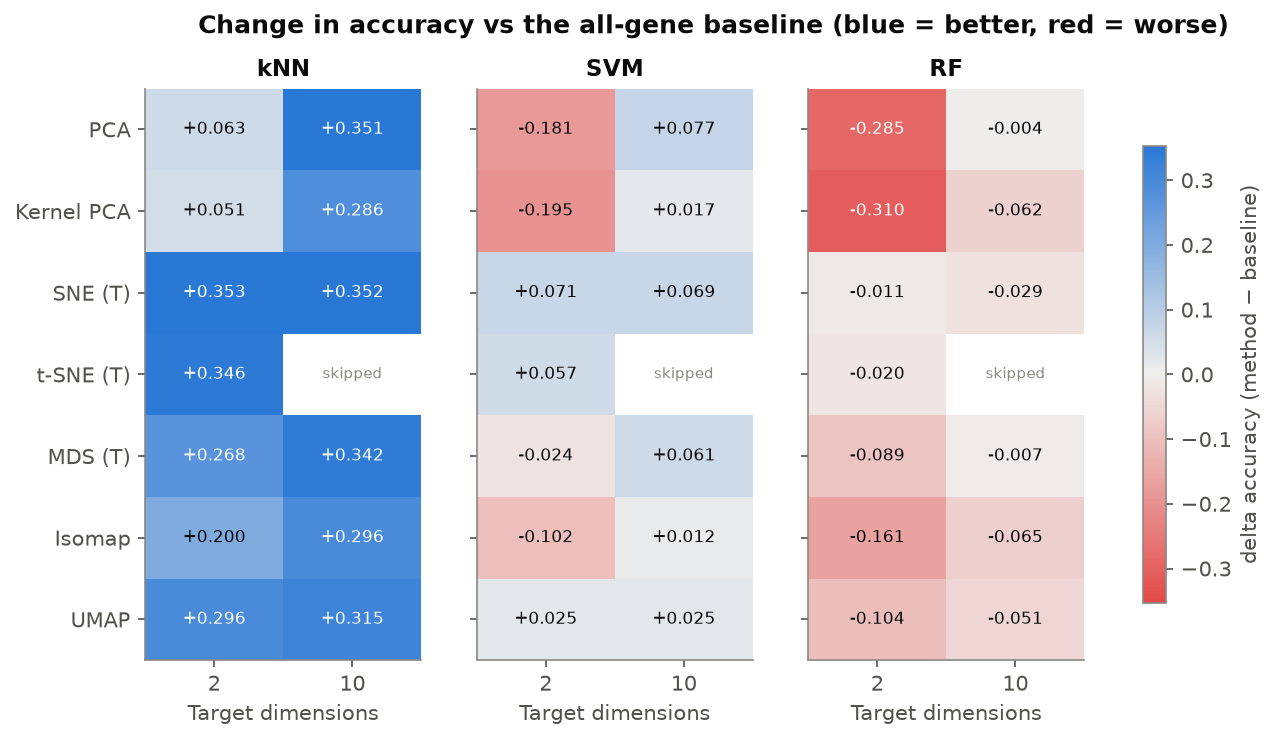

In [17]:
show('partA_delta_accuracy_heatmap.png')

**How to read this graph.** Each cell shows *method accuracy − baseline accuracy* for one method (row) at one dimension (column), with one panel per classifier. Blue means better than baseline, red means worse, and grey is about the same. "skipped" marks combinations that did not run. Read across a row to see how many dimensions a method needs to catch up with the baseline.

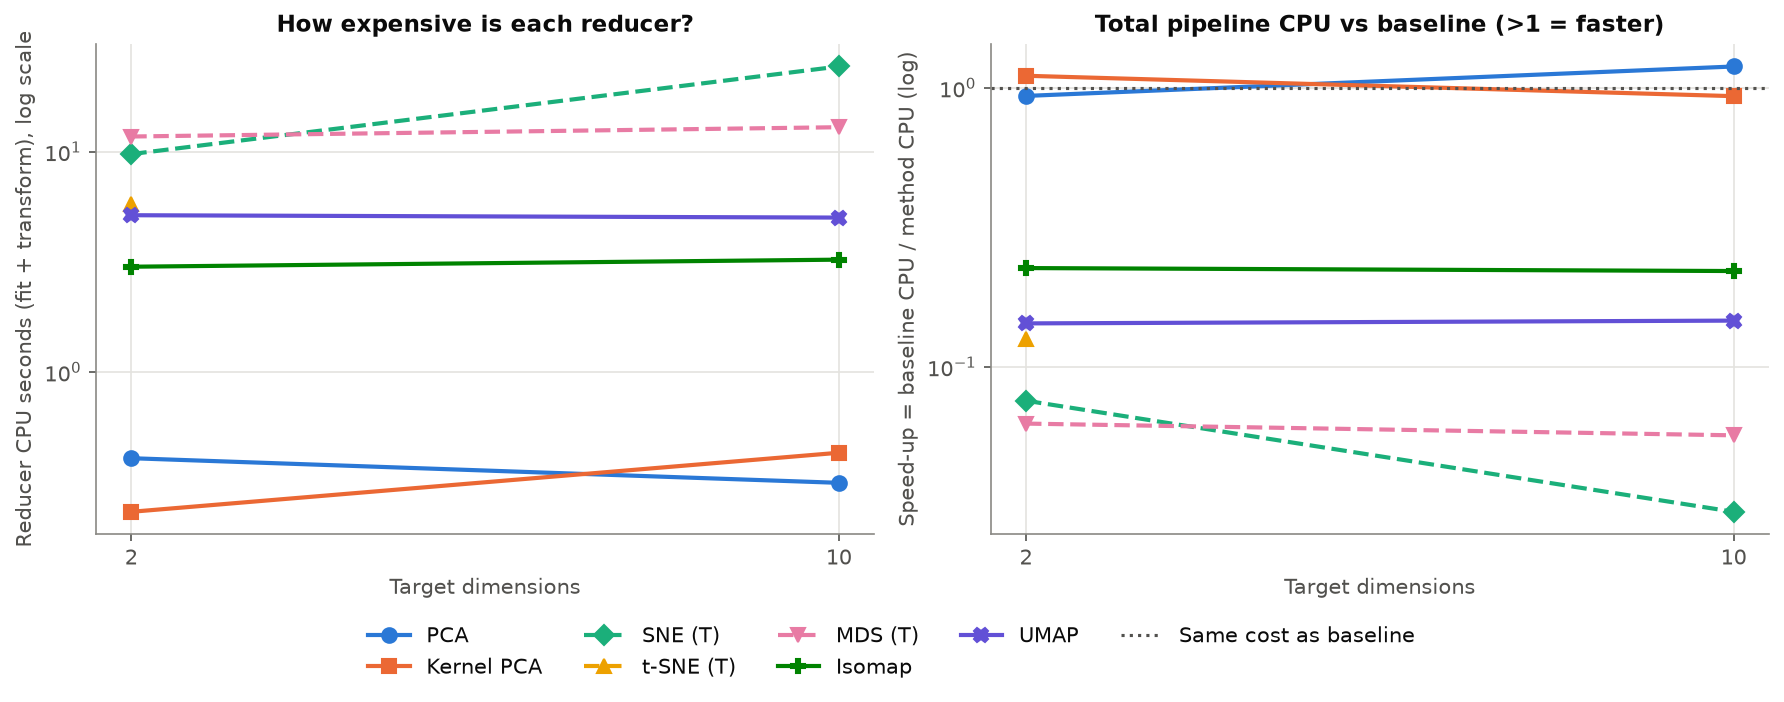

In [18]:
show('partA_cpu_time.png')

**How to read this graph.** Left: CPU seconds spent by the reducer alone (fit + transform), on a log scale. PCA and Kernel PCA take well under a second, while MDS, SNE and t-SNE take tens to hundreds of seconds. Each step up the axis is 10× more expensive. Right: **speed-up factor** = baseline CPU ÷ (reducer + classifier CPU), averaged over classifiers. Above 1 means the whole pipeline is cheaper than training on all genes. That happens mainly for PCA and Kernel PCA, because SVM's training cost drops sharply with fewer features (per-classifier numbers are in `partA_summary.csv`). Most manifold methods cost far more than they save, so they are tools for visualisation and denoising, not for speed.

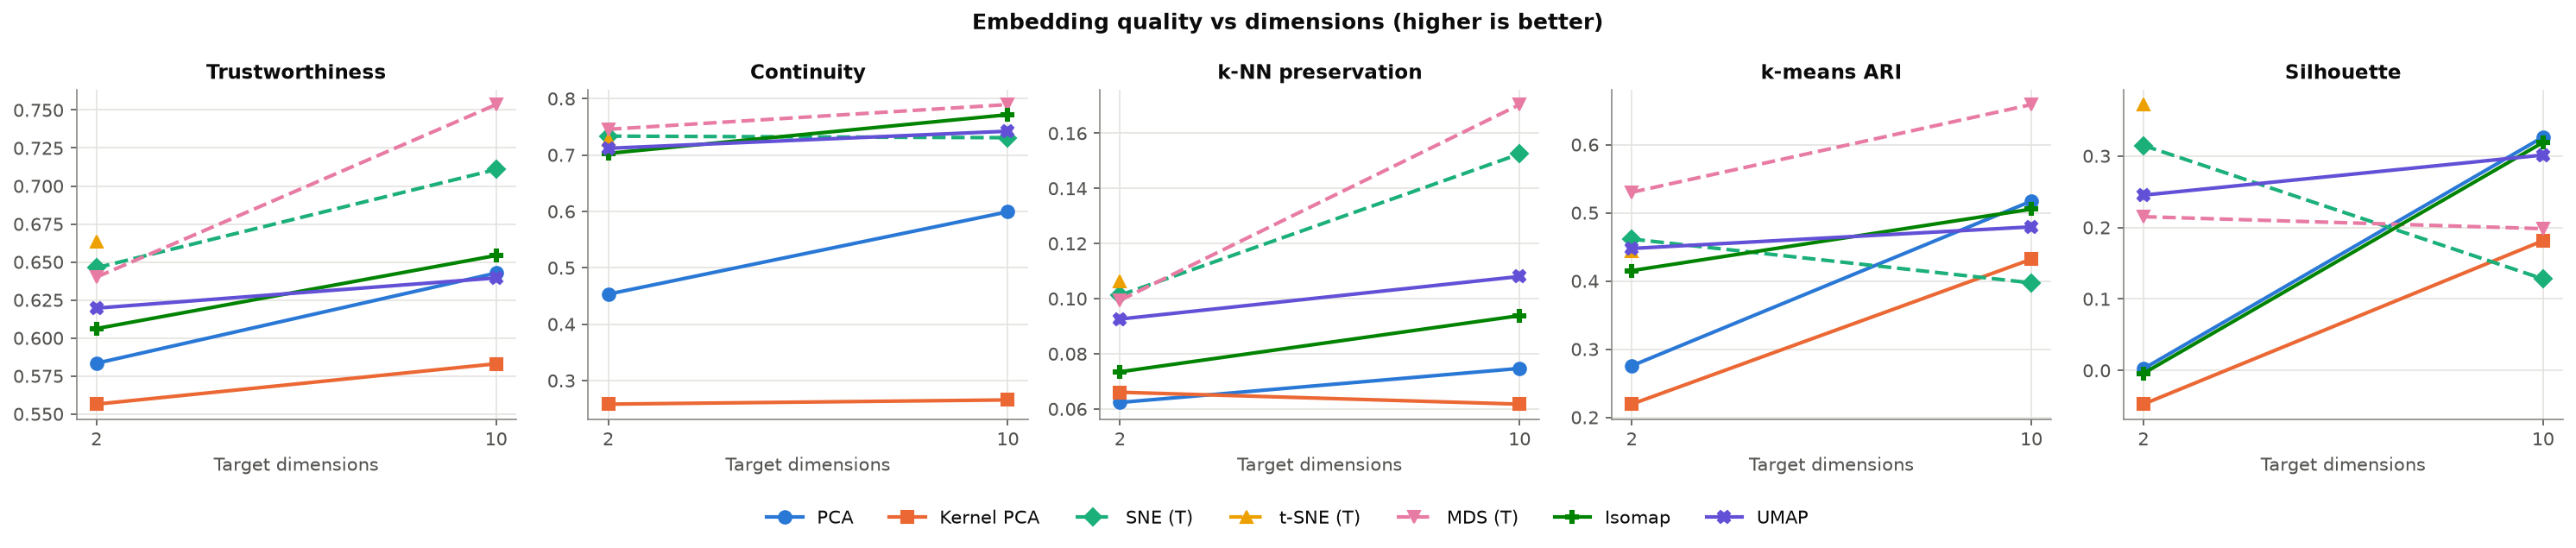

trustworthiness  continuity  knn_preservation    ari  \
method     dim                                                         
Isomap     2              0.606       0.703             0.073  0.415   
           10             0.654       0.771             0.094  0.505   
Kernel PCA 2              0.556       0.258             0.066  0.219   
           10             0.583       0.266             0.062  0.432   
MDS        2              0.640       0.745             0.099  0.530   
           10             0.754       0.789             0.170  0.659   
PCA        2              0.583       0.453             0.062  0.276   
           10             0.643       0.599             0.075  0.517   
SNE        2              0.646       0.733             0.101  0.461   
           10             0.711       0.731             0.152  0.397   
UMAP       2              0.620       0.712             0.093  0.448   
           10             0.639       0.742             0.108  0.479   
t-SNE      2              0.663       0.726             0.106  0.443   

                silhouette  
method     dim              
Isomap     2        -0.004  
           10        0.319  
Kernel PCA 2        -0.047  
           10        0.181  
MDS        2         0.215  
           10        0.198  
PCA        2         0.002  
           10        0.326  
SNE        2         0.315  
           10        0.128  
UMAP       2         0.245  
           10        0.301  
t-SNE      2         0.372

In [19]:
show('partA_quality_vs_dim.png')
A['quality'].groupby(['method', 'dim'])[['trustworthiness', 'continuity', 'knn_preservation', 'ari', 'silhouette']].mean()

**How to read this graph.** Five quality scores (higher is better) vs output dimensions, one line per method. Trustworthiness and continuity usually rise with more dimensions: there is more room to keep neighbourhoods. Neighbourhood methods (t-SNE, SNE, UMAP) score well on trustworthiness *in 2D*, because that is what they optimise. PCA in 2D scores poorly on continuity, because it tears apart neighbourhoods that differ along PC3, PC4 and so on. k-NN preservation looks low in absolute terms because the reference space (1,800 scaled genes) is itself noisy. Compare methods *relative* to each other. ARI and silhouette tell you whether the embedding forms clean, label-matching clusters.

Note: these are computed on ~1/5 of the cells (the first fold's test set), capped at `quality_max_cells`.

### 5.9 Is the difference real? Statistical tests

For each method × dimension × classifier we compare the per-fold scores with the baseline's scores **on the same folds** (paired):

* **Paired t-test**: is the mean difference zero? It assumes the differences are roughly normally distributed.
* **Wilcoxon signed-rank test**: the non-parametric alternative, using only the ranks of the differences. It is safer with few folds and outliers.
* **One-way ANOVA** across all methods (plus baseline) per classifier × dimension: do *any* of the methods differ?

⚠️ **Caveats.** (1) CV folds share training cells, so they are not independent, and p-values come out somewhat too small. (2) With only 5 paired values (FAST mode), Wilcoxon cannot reach p < 0.05 at all (its minimum p is 0.0625). Use the full 3 × 5 = 15 folds for real conclusions. (3) We run many tests, so expect some false positives at α = 0.05.

In [20]:
st = A['stats']
st[st.metric == 'accuracy'].sort_values('ttest_p').head(12)

,classifier,method,dim,metric,n_pairs,mean_diff_vs_baseline,ttest_stat,ttest_p,wilcoxon_stat,wilcoxon_p
15,SVM,Kernel PCA,2,accuracy,5,-0.195,-22.069,2.495e-05,0.0,0.062
2,RF,Kernel PCA,2,accuracy,5,-0.310,-14.597,1.281e-04,0.0,0.062
0,RF,Isomap,2,accuracy,5,-0.161,-12.571,2.305e-04,0.0,0.062
18,SVM,MDS,10,accuracy,5,0.061,11.344,3.442e-04,0.0,0.062
20,SVM,PCA,10,accuracy,5,0.077,10.756,4.236e-04,0.0,0.062
6,RF,PCA,2,accuracy,5,-0.285,-10.015,5.588e-04,0.0,0.062
34,kNN,SNE,2,accuracy,5,0.353,8.334,1.133e-03,0.0,0.062
35,kNN,SNE,10,accuracy,5,0.352,8.329,1.136e-03,0.0,0.062
31,kNN,MDS,10,accuracy,5,0.342,8.270,1.167e-03,0.0,0.062
13,SVM,Isomap,2,accuracy,5,-0.102,-8.047,1.295e-03,0.0,0.062


In [21]:
A['anova']

,classifier,dim,metric,n_groups,F,p_value
0,RF,2,accuracy,8,54.469,5.507e-16
1,RF,10,accuracy,7,8.159,3.737e-05
2,SVM,2,accuracy,8,66.996,2.623e-17
3,SVM,10,accuracy,7,13.017,5.419e-07
4,kNN,2,accuracy,8,40.930,3.352e-14
5,kNN,10,accuracy,7,47.939,1.887e-13


## 6. Part B: feature selection (keep original genes)

**Feature selection (FS)** creates no new coordinates. It *keeps a subset of the original genes* and drops the rest. The big win is **interpretability**: the result is a gene list a biologist can read, validate and turn into a cheap lab panel.

| | Dimensionality reduction | Feature selection |
|---|---|---|
| Output | new axes (mixtures of genes) | a subset of real genes |
| Interpretability | low (PC1 = 0.3·CD3D − 0.2·LYZ + …) | high (CD3D, LYZ, …) |
| Uses labels? | no (all methods here are unsupervised) | usually yes (filter/embedded methods) |

**Leakage:** supervised selectors look at the labels, so selecting genes on *all* cells and then cross-validating is a classic, serious leak (demonstrated in §9). We put the selector **inside a sklearn `Pipeline`** (`select → scale → classifier`), so it is re-fit on every training fold.

### The selectors

In [22]:
def fs_figure(method, fname):
    """Left: sorted gene scores (how fast does information drop off?).
       Right: expression of the method's #1 gene in each cell type."""
    s, cpu, _ = gene_scores(method, ds.X, ds.y, SEED, cfg['partB'])
    order = top_k(s, len(s))
    best = order[0]
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw=dict(width_ratios=[1, 1.4]))
    axes[0].plot(np.arange(1, len(s) + 1), s[order], color=plots.CAT[0])
    axes[0].set(xscale='log', xlabel='Gene rank (log)', ylabel='Score', title=f'{method}: sorted scores  (CPU {cpu:.2f}s)')
    data = [ds.X[ds.y == c, best] for c in range(len(ds.class_names))]
    bp = axes[1].boxplot(data, vert=False, patch_artist=True, widths=0.6, showfliers=False)
    for patch, col in zip(bp['boxes'], plots.palette(ds.class_names).values()):
        patch.set_facecolor(col); patch.set_alpha(0.75)
    axes[1].set_yticks(range(1, len(ds.class_names) + 1), ds.class_names)
    axes[1].set(xlabel='log-normalised expression', title=f'Top gene: {ds.gene_names[best]}')
    fig.tight_layout(); fig.savefig(FIG / fname, dpi=DPI, bbox_inches='tight'); plt.show()
    print('Top 10:', ', '.join(ds.gene_names[order[:10]]))

#### 6.1 Variance Threshold (unsupervised filter)
* **Idea:** genes that barely change between cells cannot tell cell types apart, so keep the *k* genes with the highest variance. It never looks at the labels.
* **Formula:** $\mathrm{Var}(x_g) = \frac1n\sum_i (x_{ig} - \bar x_g)^2$.
* **Strengths:** extremely fast, label-free (no leakage risk from labels), and is essentially how "highly variable genes" are chosen.
* **Weaknesses:** high variance ≠ useful. A gene may vary because of stress or cell cycle, not cell type. It **must** run on unscaled data (§2).
* **Analogy:** in a class photo, look first at whoever is moving the most. They are interesting, but not necessarily for the reason you care about.

In [23]:
fs_figure('Variance Threshold', 'partB_method_variance.png')

Top 10: CST3, TYROBP, S100A8, LGALS1, HLA-DPB1, LTB, NKG7, HLA-DRB1, HLA-DPA1, S100A6


**How to read this graph.** Left: gene scores sorted from best to worst (log x-axis). A steep drop means a few genes carry most of the signal. A flat curve means information is spread across many genes. Right: the distribution of the top-ranked gene in each cell type (box = middle 50 % of cells, line = median). A useful marker has one or two boxes clearly shifted away from the rest.

#### 6.2 ANOVA F-test (supervised filter)
* **Idea:** for each gene, compare how far the cell-type *means* are from each other (between-group variance) with how spread out cells are *within* each type (within-group variance).
* **Formula:** $F = \dfrac{\sum_c n_c(\bar x_c - \bar x)^2/(C-1)}{\sum_c\sum_{i\in c}(x_i - \bar x_c)^2/(n-C)}$.
* **Strengths:** fast, uses labels, has a classic statistical interpretation.
* **Weaknesses:** looks at one gene at a time (ignores redundancy, so it can pick 10 genes telling the same story), assumes roughly normal data, and is dominated by a type with an extreme mean (e.g. the platelet genes *PPBP* and *PF4* in megakaryocytes).
* **Analogy:** grading each exam question by how well it separates top students from weak students, one question at a time.

In [24]:
fs_figure('ANOVA F-test', 'partB_method_anova.png')

Top 10: PPBP, PF4, TYROBP, CST3, LST1, S100A8, NKG7, CD79A, FCER1G, GNG11


**How to read this graph.** If the top gene is *PPBP* or *PF4*, its boxes are near zero for every type except Megakaryocytes. That is a huge between-type difference, hence a huge F. It's perfect for spotting the rarest type, but it says nothing about telling CD4 from CD8 T cells. Single-gene scores optimise for *one* contrast at a time.

#### 6.3 Mutual Information (supervised, nonlinear filter)
* **Idea:** how much does knowing a gene's expression reduce uncertainty about the cell type? It captures *any* dependency, not just shifts in the mean.
* **Formula:** $I(X;Y) = \sum_{x,y} p(x,y)\log\frac{p(x,y)}{p(x)p(y)}$, estimated with a k-nearest-neighbour estimator for continuous genes.
* **Strengths:** model-free, captures nonlinear and multi-type patterns.
* **Weaknesses:** the estimate is noisy (randomness, so we fix `random_state`), it is the slowest of the filters, and it is still one gene at a time.
* **Analogy:** playing "20 questions": which single question about one gene gets you closest to guessing the cell type?

In [25]:
fs_figure('Mutual Information', 'partB_method_mi.png')

Top 10: TYROBP, CST3, LST1, FCER1G, HLA-DPA1, AIF1, HLA-DRB1, S100A6, S100A8, LGALS1


**How to read this graph.** MI favours genes that split the cells into large groups (e.g. *TYROBP* or *CST3*, which are on in all myeloid/NK cells and off in lymphocytes). Such a gene resolves a lot of uncertainty about many cells at once, unlike *PPBP*, which only identifies 15 cells.

#### 6.4 Fisher Score (supervised filter)
* **Idea:** between-type scatter of the gene divided by within-type scatter, i.e. the 1-gene version of Fisher's discriminant analysis.
* **Formula:** $\mathrm{FS}_g = \dfrac{\sum_c n_c(\mu_c - \mu)^2}{\sum_c n_c \sigma_c^2}$.
* **Insight:** compare this with the ANOVA F formula. The numerator and denominator are the same sums, just without the degrees-of-freedom factors $(C-1)$ and $(n-C)$. So $F = \mathrm{FS}\cdot\frac{n-C}{C-1}$: **Fisher score and ANOVA F rank genes identically.** You'll see identical lines in the plots below. That is the maths working, not a bug.
* **Analogy:** the same exam-grading idea as ANOVA, with a different marking scale but the same ranking of questions.

In [26]:
fs_figure('Fisher Score', 'partB_method_fisher.png')

Top 10: PPBP, PF4, TYROBP, CST3, LST1, S100A8, NKG7, CD79A, FCER1G, GNG11


**How to read this graph.** It is identical to ANOVA's (the same top gene, the same shape), with only the y-axis scale changed.

#### 6.5 Lasso / L1-regularised logistic regression (embedded method, optional extra)
* **Idea:** fit a multinomial logistic regression that predicts cell type from all genes, with an **L1 penalty** $\;\lambda\sum_g |w_g|$ that pushes most coefficients to exactly zero. Genes with non-zero weights are "selected". The score is the largest |weight| over the cell types.
* **Key hyperparameter:** `lasso_C` = 1/λ. Smaller C gives a stronger penalty and fewer genes.
* **Strengths:** looks at genes *jointly*, so redundant genes are dropped (if *CD79A* is chosen, *CD79B* adds little). It gives marker panels that cover all types.
* **Weaknesses:** the slowest method here, needs scaling, and its choice among correlated genes is somewhat arbitrary, which makes it less stable (see the stability check).
* **Analogy:** a strict budget. Every gene costs money, so you only buy the ones that add new information.

In [27]:
fs_figure('Lasso (L1)', 'partB_method_lasso.png')

Top 10: S100A8, CCL5, CD79A, GZMK, LGALS2, FCGR3A, HLA-DRB1, NKG7, FCER1A, MS4A1


**How to read this graph.** The sorted-score curve drops to exactly zero after a while: those are the genes Lasso switched off. The top-10 list typically covers *different* cell types (B-cell, NK, monocyte and T-cell genes), unlike the univariate filters, which stack up genes for the easiest contrasts.

### 6.6 The benchmark: accuracy vs number of genes
For each selector, *k* ∈ `k_values`, classifier and CV fold: `Pipeline([TopKSelector(method, k), scaler, classifier])` is fit on the training fold and evaluated on the test fold. Gene scores are cached per training fold, so trying 5 values of *k* costs one scoring pass. The CPU time reported for selection is that full scoring cost.

In [28]:
B = run_partB(ds, cfg, base, splits)        # also runs the bootstrap stability check
B['summary'][['method', 'k', 'classifier', 'accuracy', 'macro_f1', 'delta_accuracy', 'select_cpu', 'total_cpu', 'speedup_cpu']] \
    .sort_values(['classifier', 'k', 'accuracy'], ascending=[True, True, False])

05:32:33  Part B: Variance Threshold, k = [10, 50]


05:32:36    done in 2.6s


05:32:36  Part B: ANOVA F-test, k = [10, 50]


05:32:38    done in 2.5s


05:32:38  Part B: Mutual Information, k = [10, 50]


...

05:34:38    figure → /mnt/D/EJUST/subjects/AML/Task_one_fashion_mnist/outputs/figures/partB_cpu_time.png


05:34:39    figure → /mnt/D/EJUST/subjects/AML/Task_one_fashion_mnist/outputs/figures/partB_top20_genes.png


05:34:39    figure → /mnt/D/EJUST/subjects/AML/Task_one_fashion_mnist/outputs/figures/partB_method_jaccard.png


05:34:39    figure → /mnt/D/EJUST/subjects/AML/Task_one_fashion_mnist/outputs/figures/partB_stability.png


,method,k,classifier,accuracy,macro_f1,delta_accuracy,select_cpu,total_cpu,speedup_cpu
2,Variance Threshold,10,RF,0.904,0.737,-0.015,0.002,0.189,1.675
26,Lasso (L1),10,RF,0.902,0.750,-0.017,10.864,11.041,0.029
8,ANOVA F-test,10,RF,0.834,0.743,-0.086,0.004,0.182,1.739
20,Fisher Score,10,RF,0.834,0.743,-0.086,0.002,0.180,1.757
14,Mutual Information,10,RF,0.818,0.724,-0.102,0.256,0.443,0.713
11,ANOVA F-test,50,RF,0.935,0.881,0.016,0.004,0.195,1.621
23,Fisher Score,50,RF,0.935,0.881,0.016,0.002,0.194,1.625
29,Lasso (L1),50,RF,0.934,0.864,0.015,10.864,11.054,0.029
17,Mutual Information,50,RF,0.931,0.852,0.011,0.256,0.456,0.692
5,Variance Threshold,50,RF,0.928,0.859,0.009,0.002,0.209,1.514


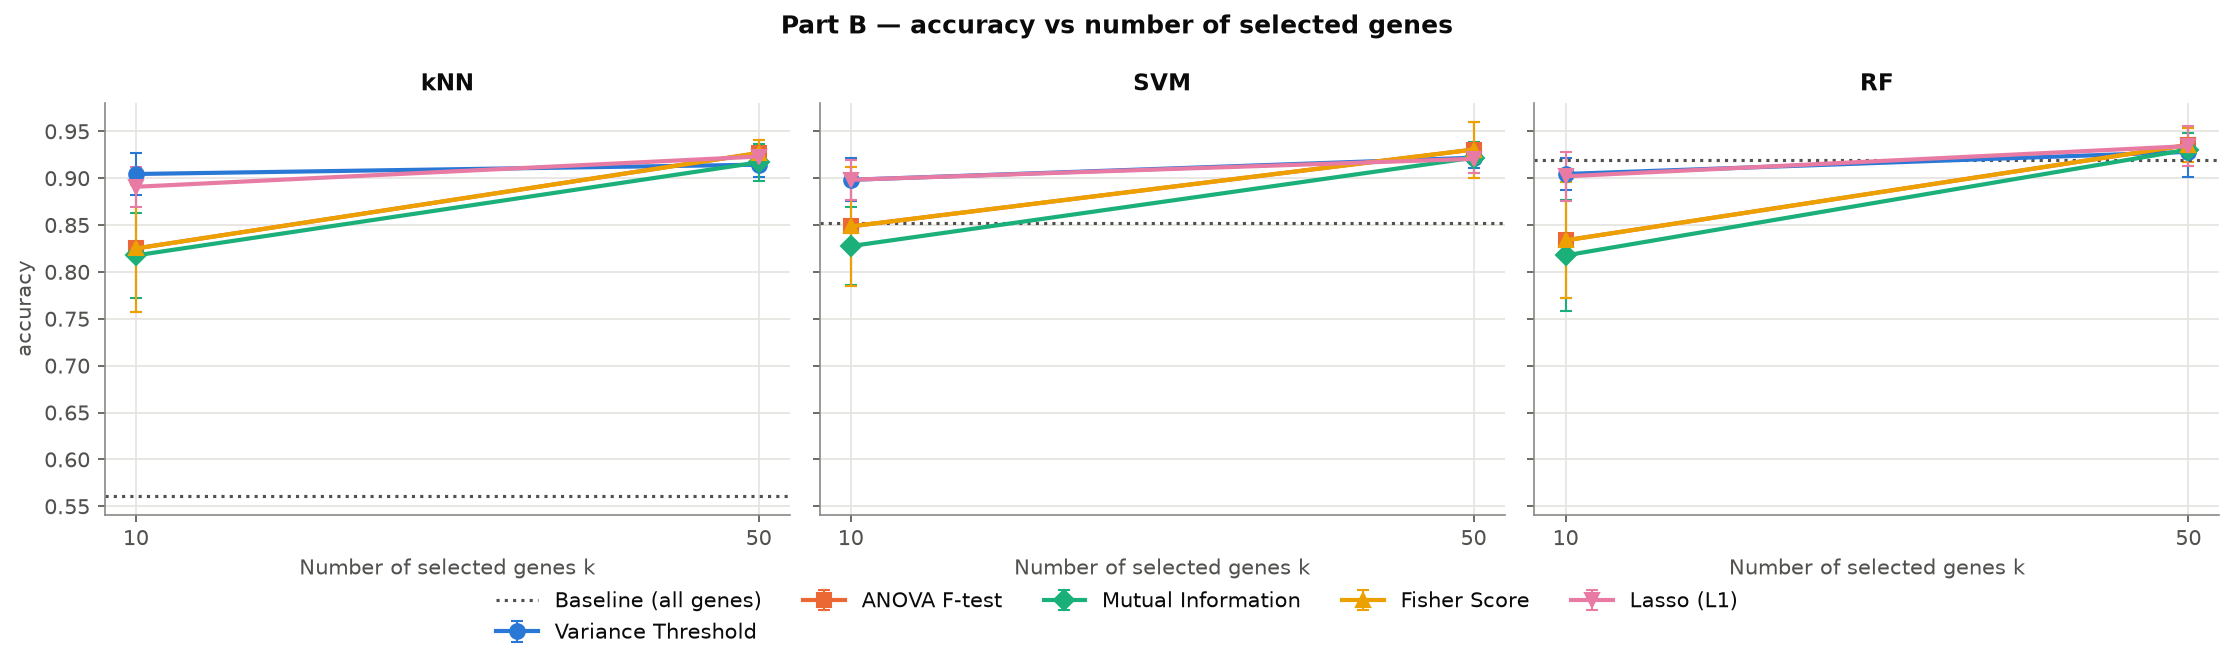

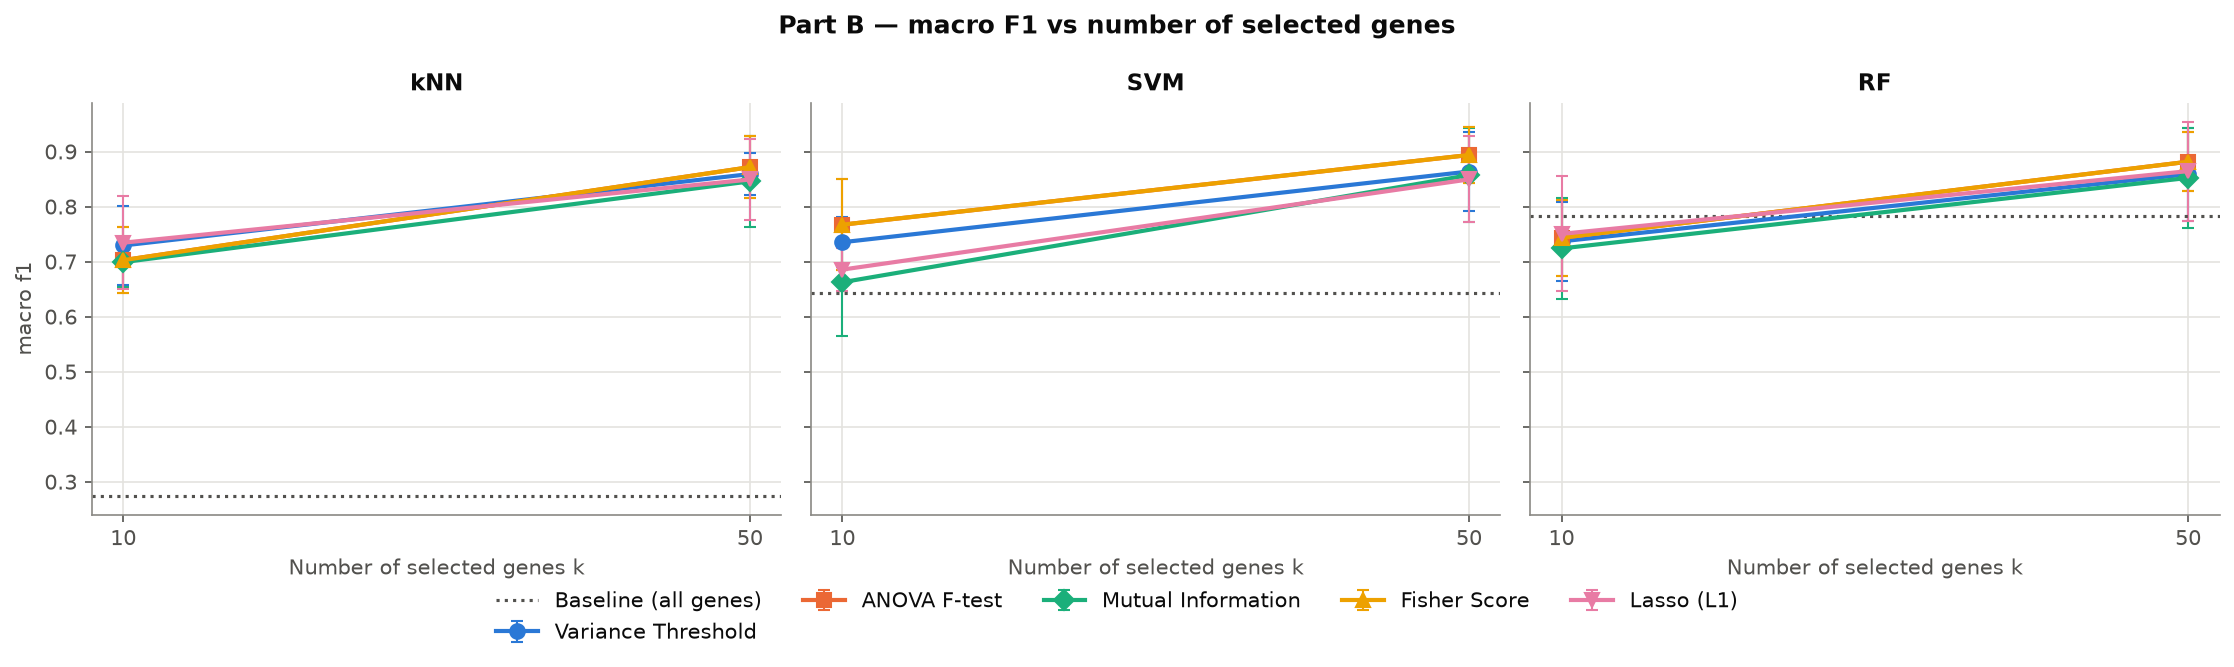

In [29]:
show('partB_accuracy_vs_k.png')
show('partB_f1_vs_k.png')

**How to read these graphs.** The x-axis is the number of kept genes (log scale) and the y-axis is mean CV accuracy or macro-F1, with one line per selector and one panel per classifier. The dotted line is the all-gene baseline. A good selector climbs quickly: high accuracy with few genes. Expect ANOVA and Fisher lines to overlap exactly (§6.4). With very few genes (10), methods that cover *many* types (Lasso, Variance) tend to beat those obsessed with one contrast (ANOVA/Fisher on platelet genes). By ~50–100 genes, most selectors match or beat the all-gene baseline, for k-NN dramatically so: removing noise genes restores meaningful distances.

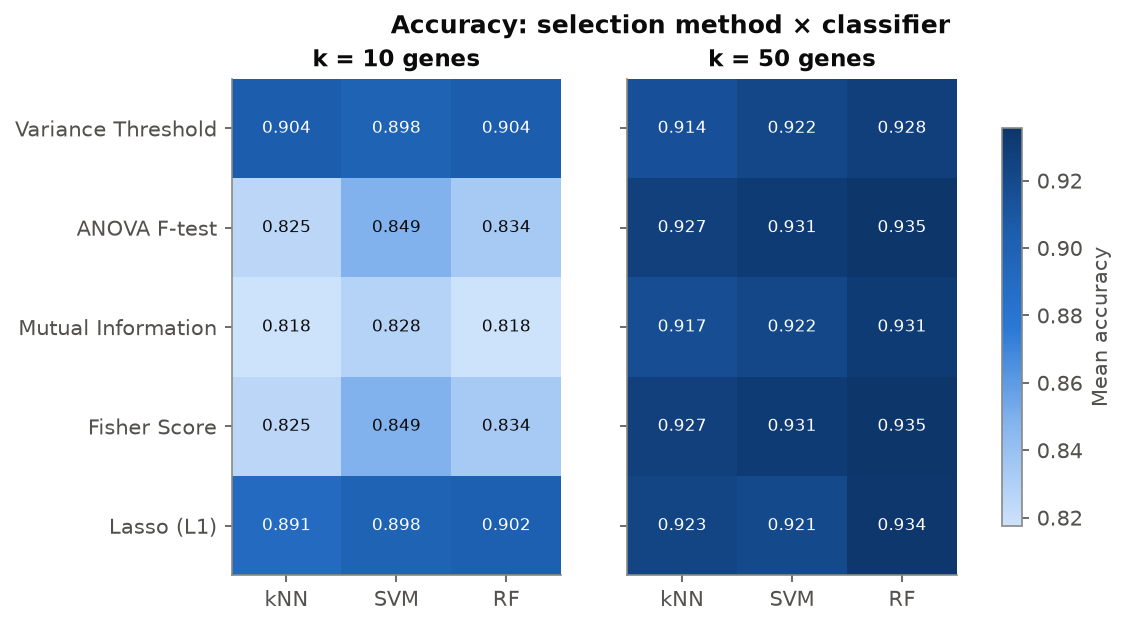

In [30]:
show('partB_heatmap_accuracy.png')

**How to read this graph.** Rows are selectors, columns are classifiers, and there is one panel per *k*. Darker blue means higher mean accuracy, and the number in each cell is the exact value. Read down a column to rank the selectors for one classifier, and across panels to see how much adding genes helps.

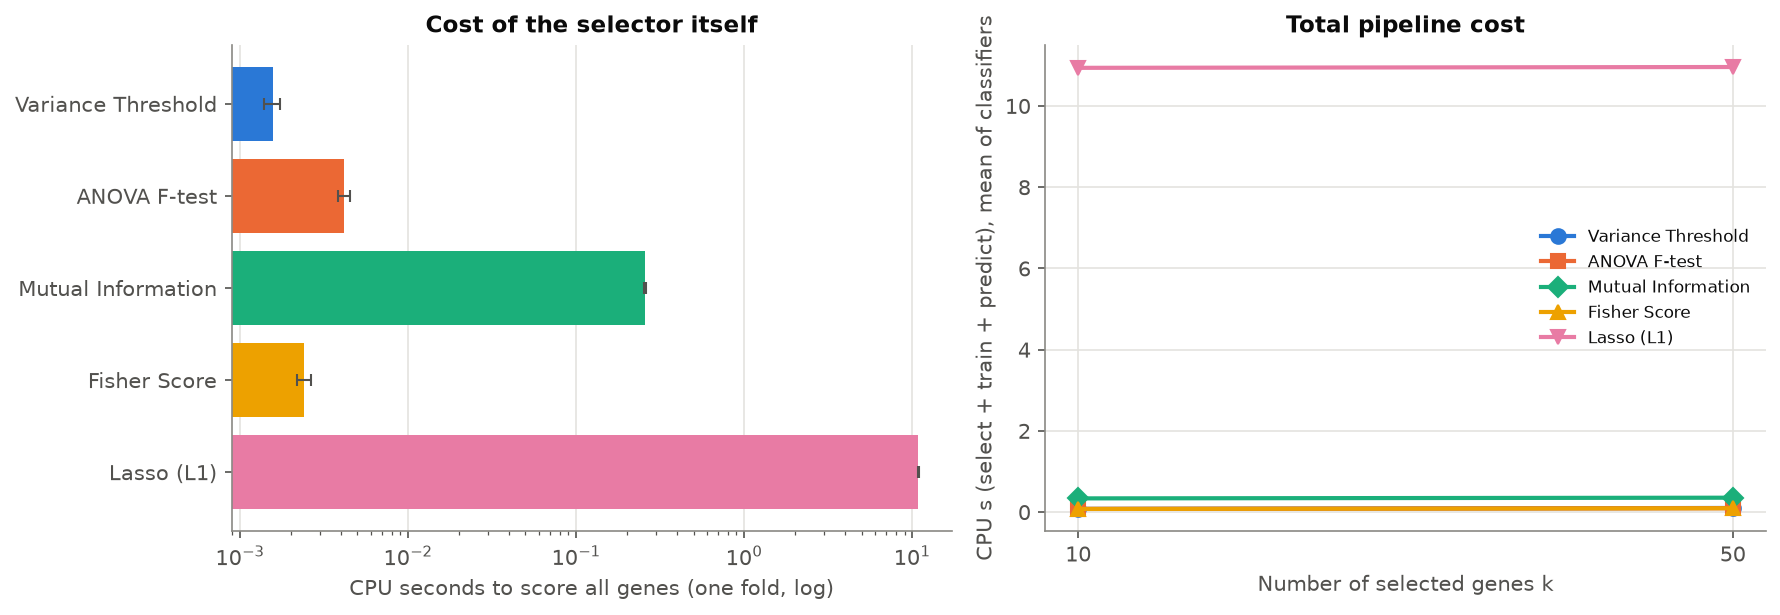

In [31]:
show('partB_cpu_time.png')

**How to read this graph.** Left: CPU time to score all genes once (log scale). Variance, ANOVA and Fisher are nearly free, mutual information costs seconds, and Lasso costs the most. Right: total CPU for selection + training + prediction vs *k*. Because classifiers train much faster on 10–200 genes than on 1,800, cheap filters make the whole pipeline faster than the baseline.

### 6.7 Which genes were chosen? Are they known immune markers?
To *interpret* the methods (not to evaluate them), we rank genes on all cells and list each method's top 20. Genes from a canonical PBMC marker list (`markers:` in `config.yaml`, from the Seurat/scanpy PBMC3k tutorials) are starred.

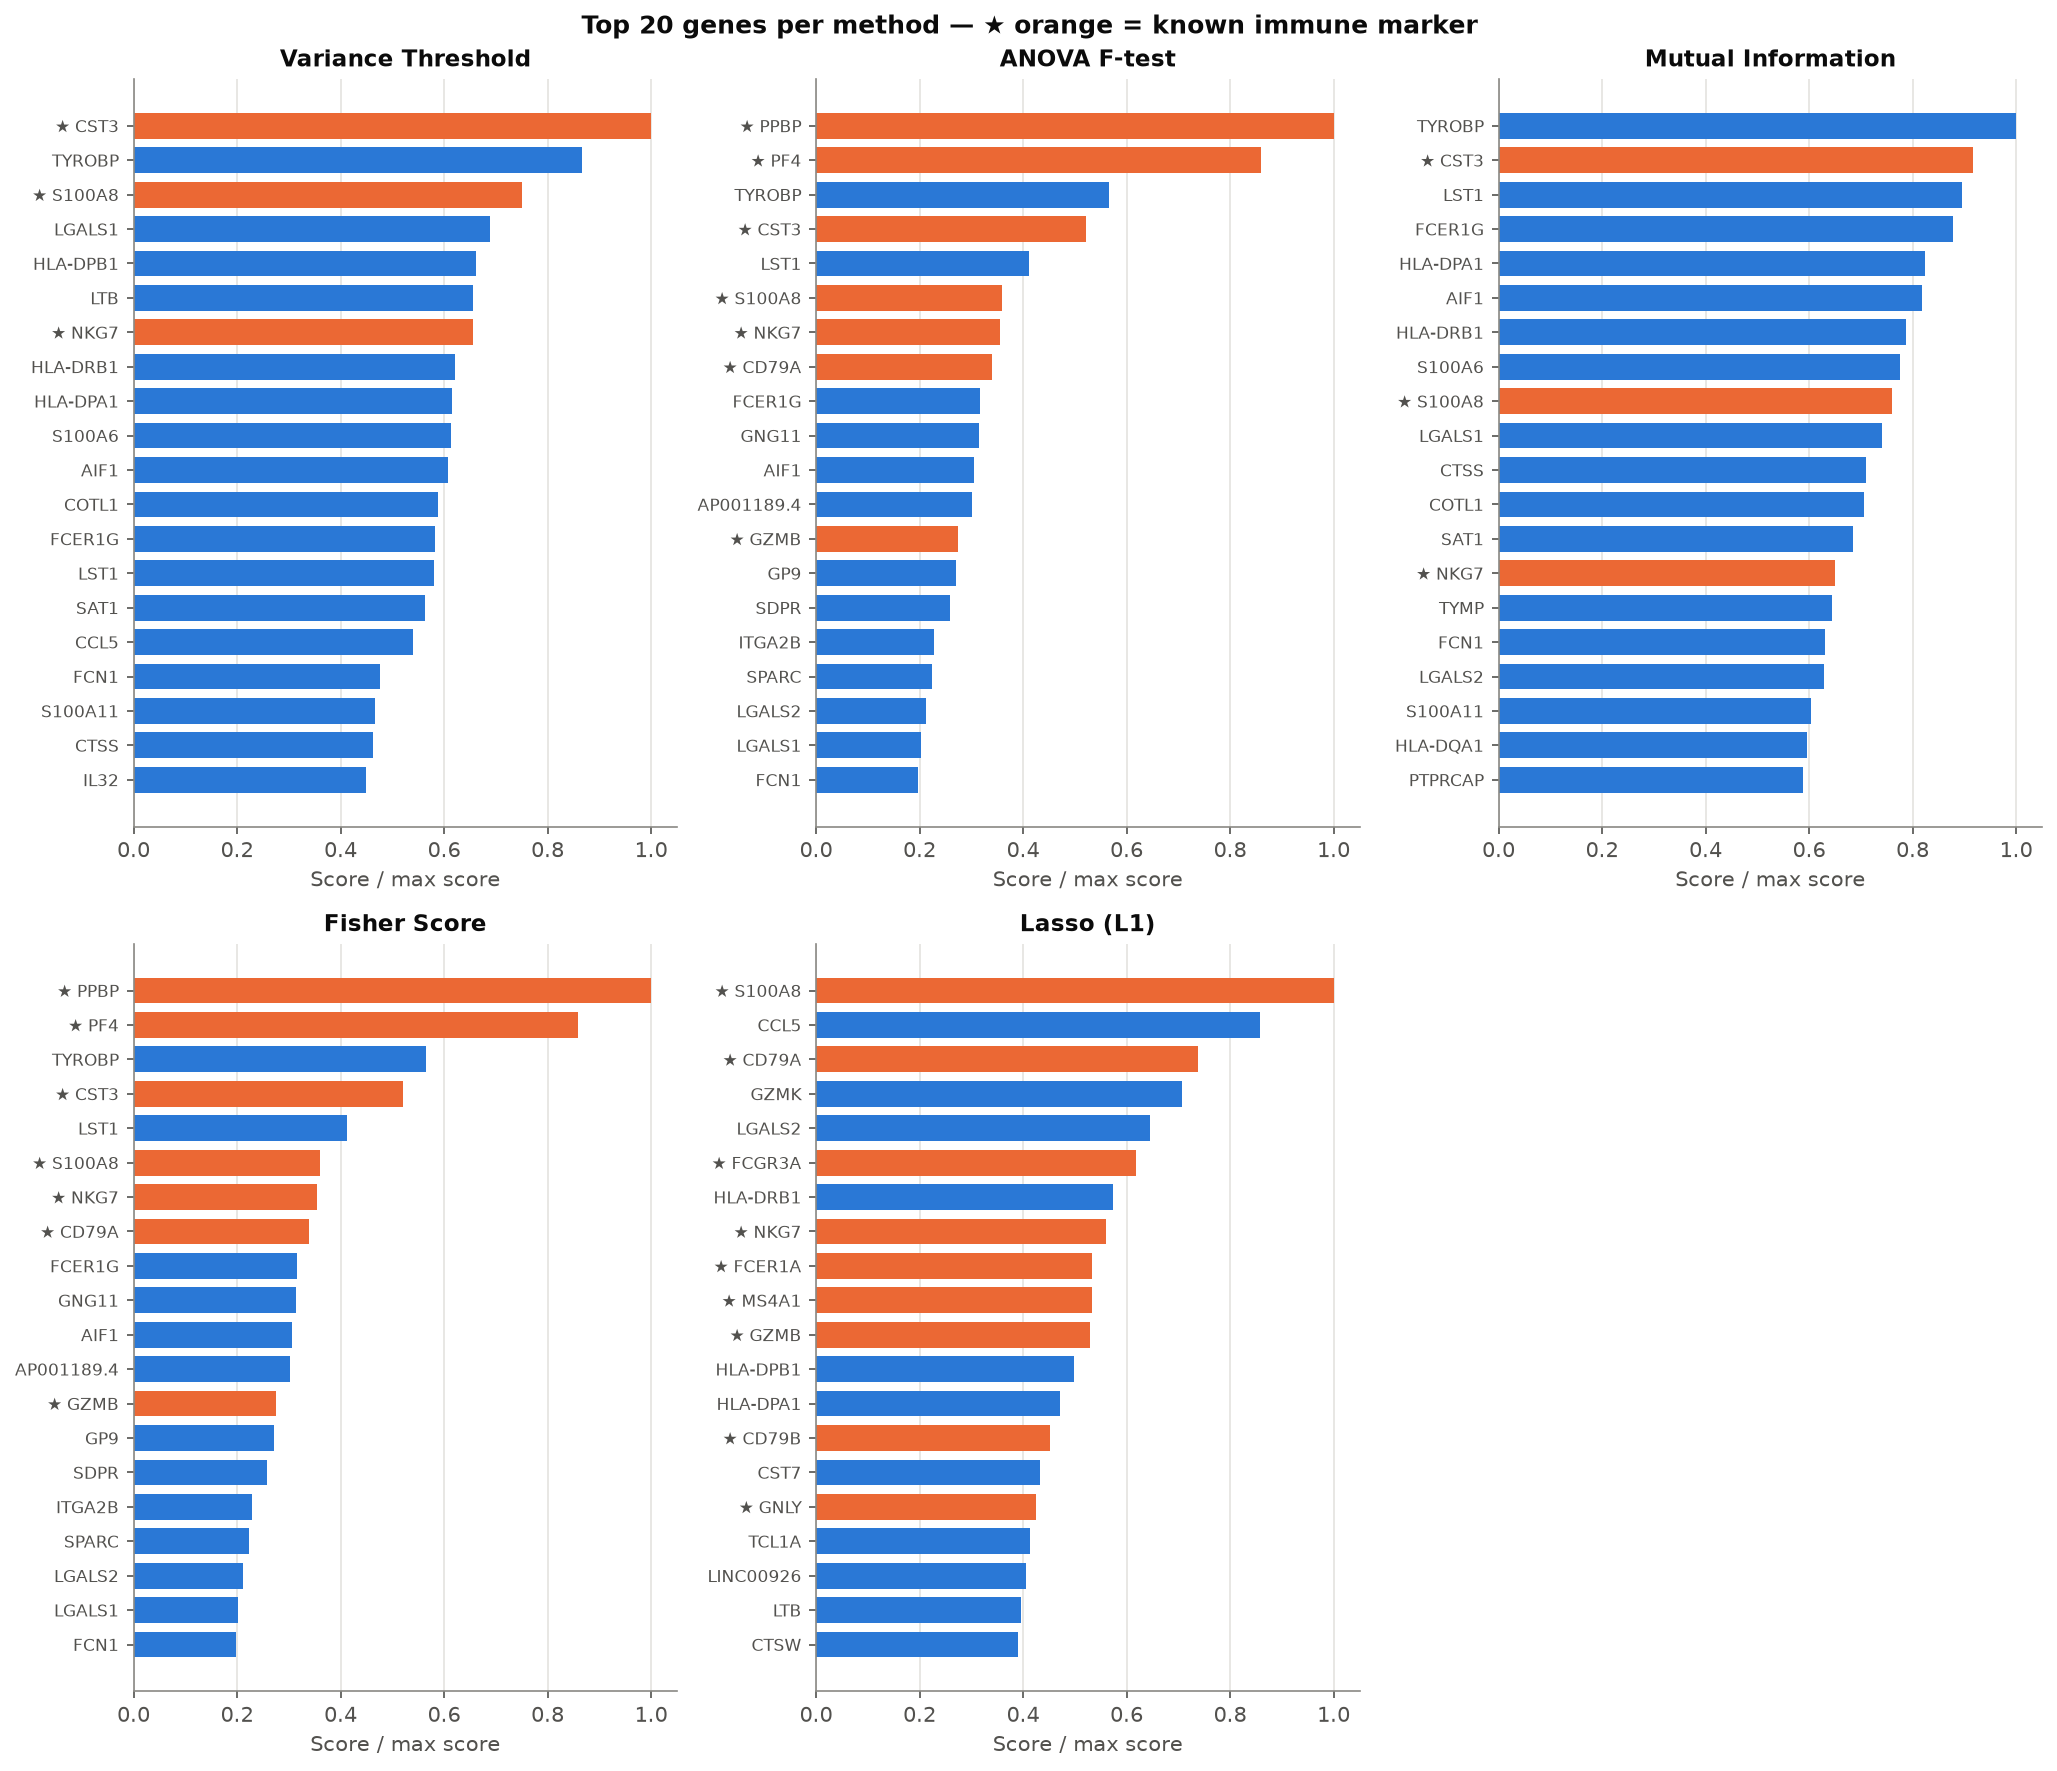

,method,n_markers,markers
0,ANOVA F-test,7,"PPBP, PF4, CST3, S100A8, NKG7, CD79A, GZMB"
1,Fisher Score,7,"PPBP, PF4, CST3, S100A8, NKG7, CD79A, GZMB"
2,Lasso (L1),9,"S100A8, CD79A, FCGR3A, NKG7, FCER1A, MS4A1, GZ..."
3,Mutual Information,3,"CST3, S100A8, NKG7"
4,Variance Threshold,3,"CST3, S100A8, NKG7"


In [32]:
show('partB_top20_genes.png')
B['markers']

**How to read this graph.** One panel per selector, showing its top 20 genes with the score divided by that method's maximum. ★ / orange marks a canonical marker gene.

**Are they real immune markers?** Mostly yes, which is a good sanity check:
* **ANOVA / Fisher** rank the **megakaryocyte/platelet genes** first (*PPBP*, *PF4*, *GNG11*, *SDPR*, *SPARC*). These are extremely specific to one rare type. Then come myeloid genes (*TYROBP*, *CST3*, *LST1*, *FCER1G*, *S100A8*) and NK/B markers (*NKG7*, *GZMB*, *CD79A*).
* **Mutual information** and **variance** favour broad **myeloid vs lymphoid** genes (*CST3*, *TYROBP*, *S100A8/A9*, *LYZ*, HLA class II genes), which split large groups of cells.
* **Lasso** spreads its picks across types: *CD79A/MS4A1* (B cells), *NKG7/GNLY/GZMB* (NK cells), *FCGR3A* (FCGR3A+ monocytes), *FCER1A* (dendritic cells), *S100A8* (CD14+ monocytes). It is the closest to a hand-curated marker panel.
* The **T-cell genes** (*CD3D*, *IL7R*, *CCR7*, *CD8A*) are rarely in anyone's top 20. T cells are mostly defined by the *absence* of other programs, and the CD4 vs CD8 contrast is subtle, which is also why CD4/CD8 T cells are the most-confused pair in every classifier.

Unstarred genes such as *LGALS1/2*, *FCN1*, *S100A6* or *CCL5* are not on our short list, but they are well-documented monocyte/NK/T-effector genes: our "marker" list is deliberately conservative.

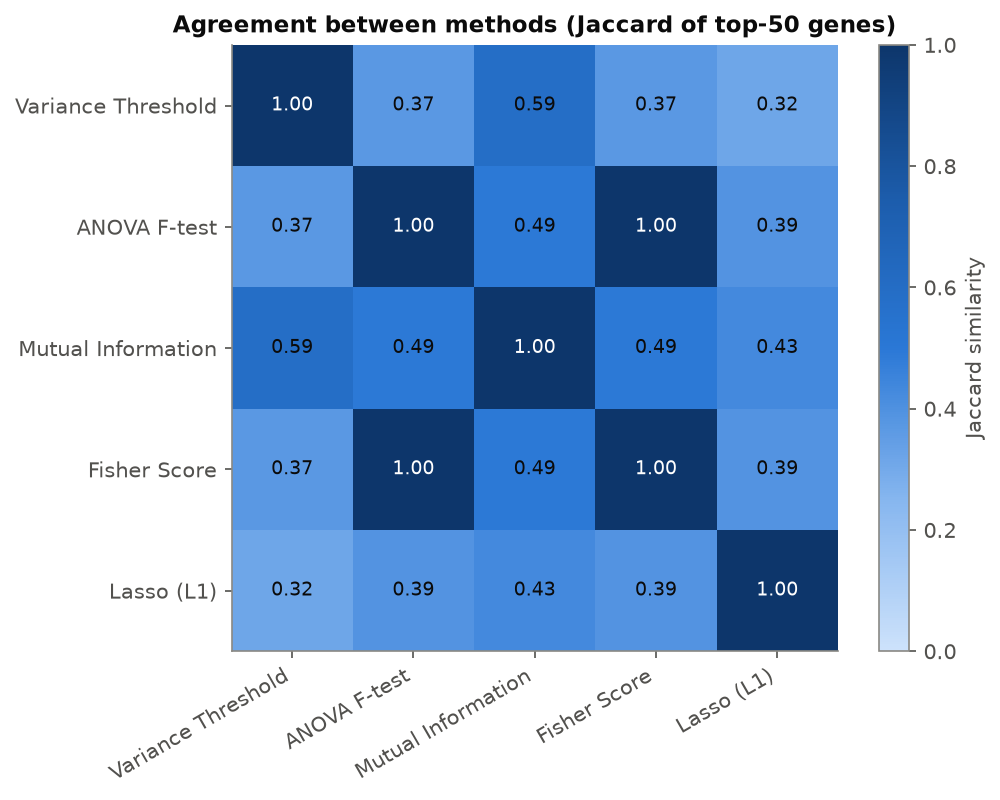

In [33]:
show('partB_method_jaccard.png')

**How to read this graph.** Each cell is the **Jaccard similarity** between two methods' top-50 gene sets, $J(A,B) = |A\cap B| / |A\cup B|$: 1 means the same genes, 0 means no overlap. The diagonal is always 1. ANOVA × Fisher = 1.00 (same ranking). Look for which methods agree most. Lasso usually agrees least with the univariate filters, because it removes redundancy.

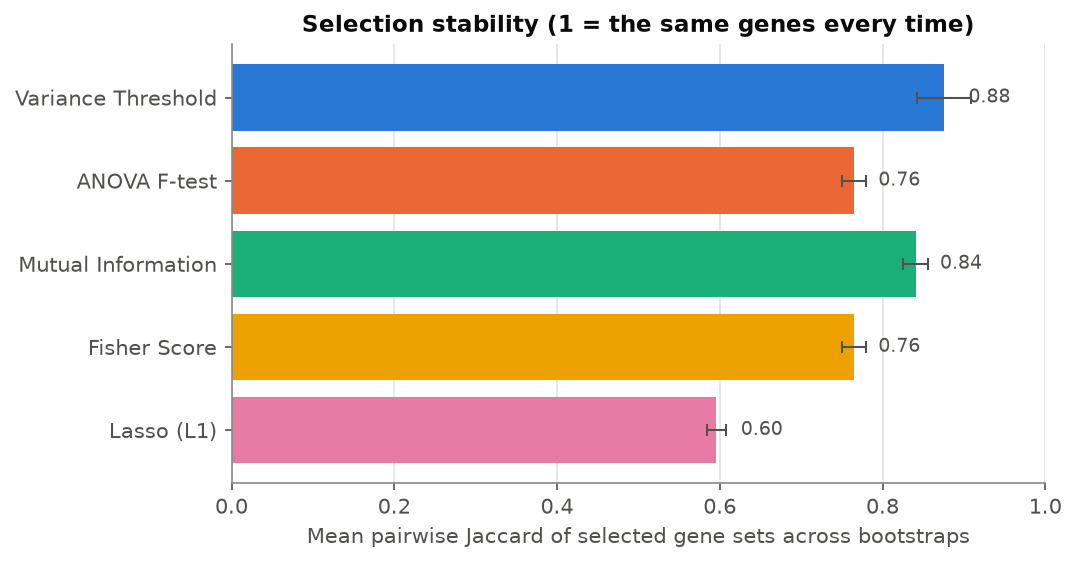

,method,k,n_bootstrap,mean_jaccard,sd_jaccard
0,Variance Threshold,50,3,0.876,0.034
1,ANOVA F-test,50,3,0.765,0.015
2,Mutual Information,50,3,0.841,0.016
3,Fisher Score,50,3,0.765,0.015
4,Lasso (L1),50,3,0.596,0.012


In [34]:
show('partB_stability.png')
B['stability']

**How to read this graph.** We resample the cells with replacement (bootstrap) several times, re-run each selector, and compute the average Jaccard similarity between the top-*k* gene sets of every pair of resamples. 1.0 means the method picks exactly the same genes regardless of which cells it saw. A stable selector gives a gene list you can trust and publish. The univariate filters are fairly stable (most of their top genes recur). Lasso is typically the least stable: among correlated genes it picks one somewhat arbitrarily, and small data changes flip the choice.

## 7. Part C: 2D maps of cell types

Exactly two output dimensions with every method, fit on all cells (this is visualisation, not evaluation). All panels share the same colour per cell type and a numbered label at each type's median. Under each panel:
* **CPU**: seconds to compute the map,
* **trust**: trustworthiness, i.e. are 2D neighbours true neighbours?
* **kNN acc**: 5-fold CV accuracy of a k-NN classifier *on the 2D coordinates*, i.e. how separable the types are in the picture.

The 2D embeddings computed in Part A's method sections are reused, so nothing is recomputed.

05:34:39  Part C: PCA → 2D


05:34:39  Part C: Kernel PCA → 2D


05:34:40  Part C: SNE → 2D


05:34:40  Part C: t-SNE → 2D


05:34:40  Part C: MDS → 2D


...

05:34:41  Part C: UMAP → 2D


05:34:42    table  → /mnt/D/EJUST/subjects/AML/Task_one_fashion_mnist/outputs/tables/partC_2d_metrics.csv


05:34:42    figure → /mnt/D/EJUST/subjects/AML/Task_one_fashion_mnist/outputs/figures/partC_2d_grid_dr.png


05:34:42    figure → /mnt/D/EJUST/subjects/AML/Task_one_fashion_mnist/outputs/figures/partC_2d_grid_fs.png


05:34:43    figure → /mnt/D/EJUST/subjects/AML/Task_one_fashion_mnist/outputs/figures/partC_2d_summary.png


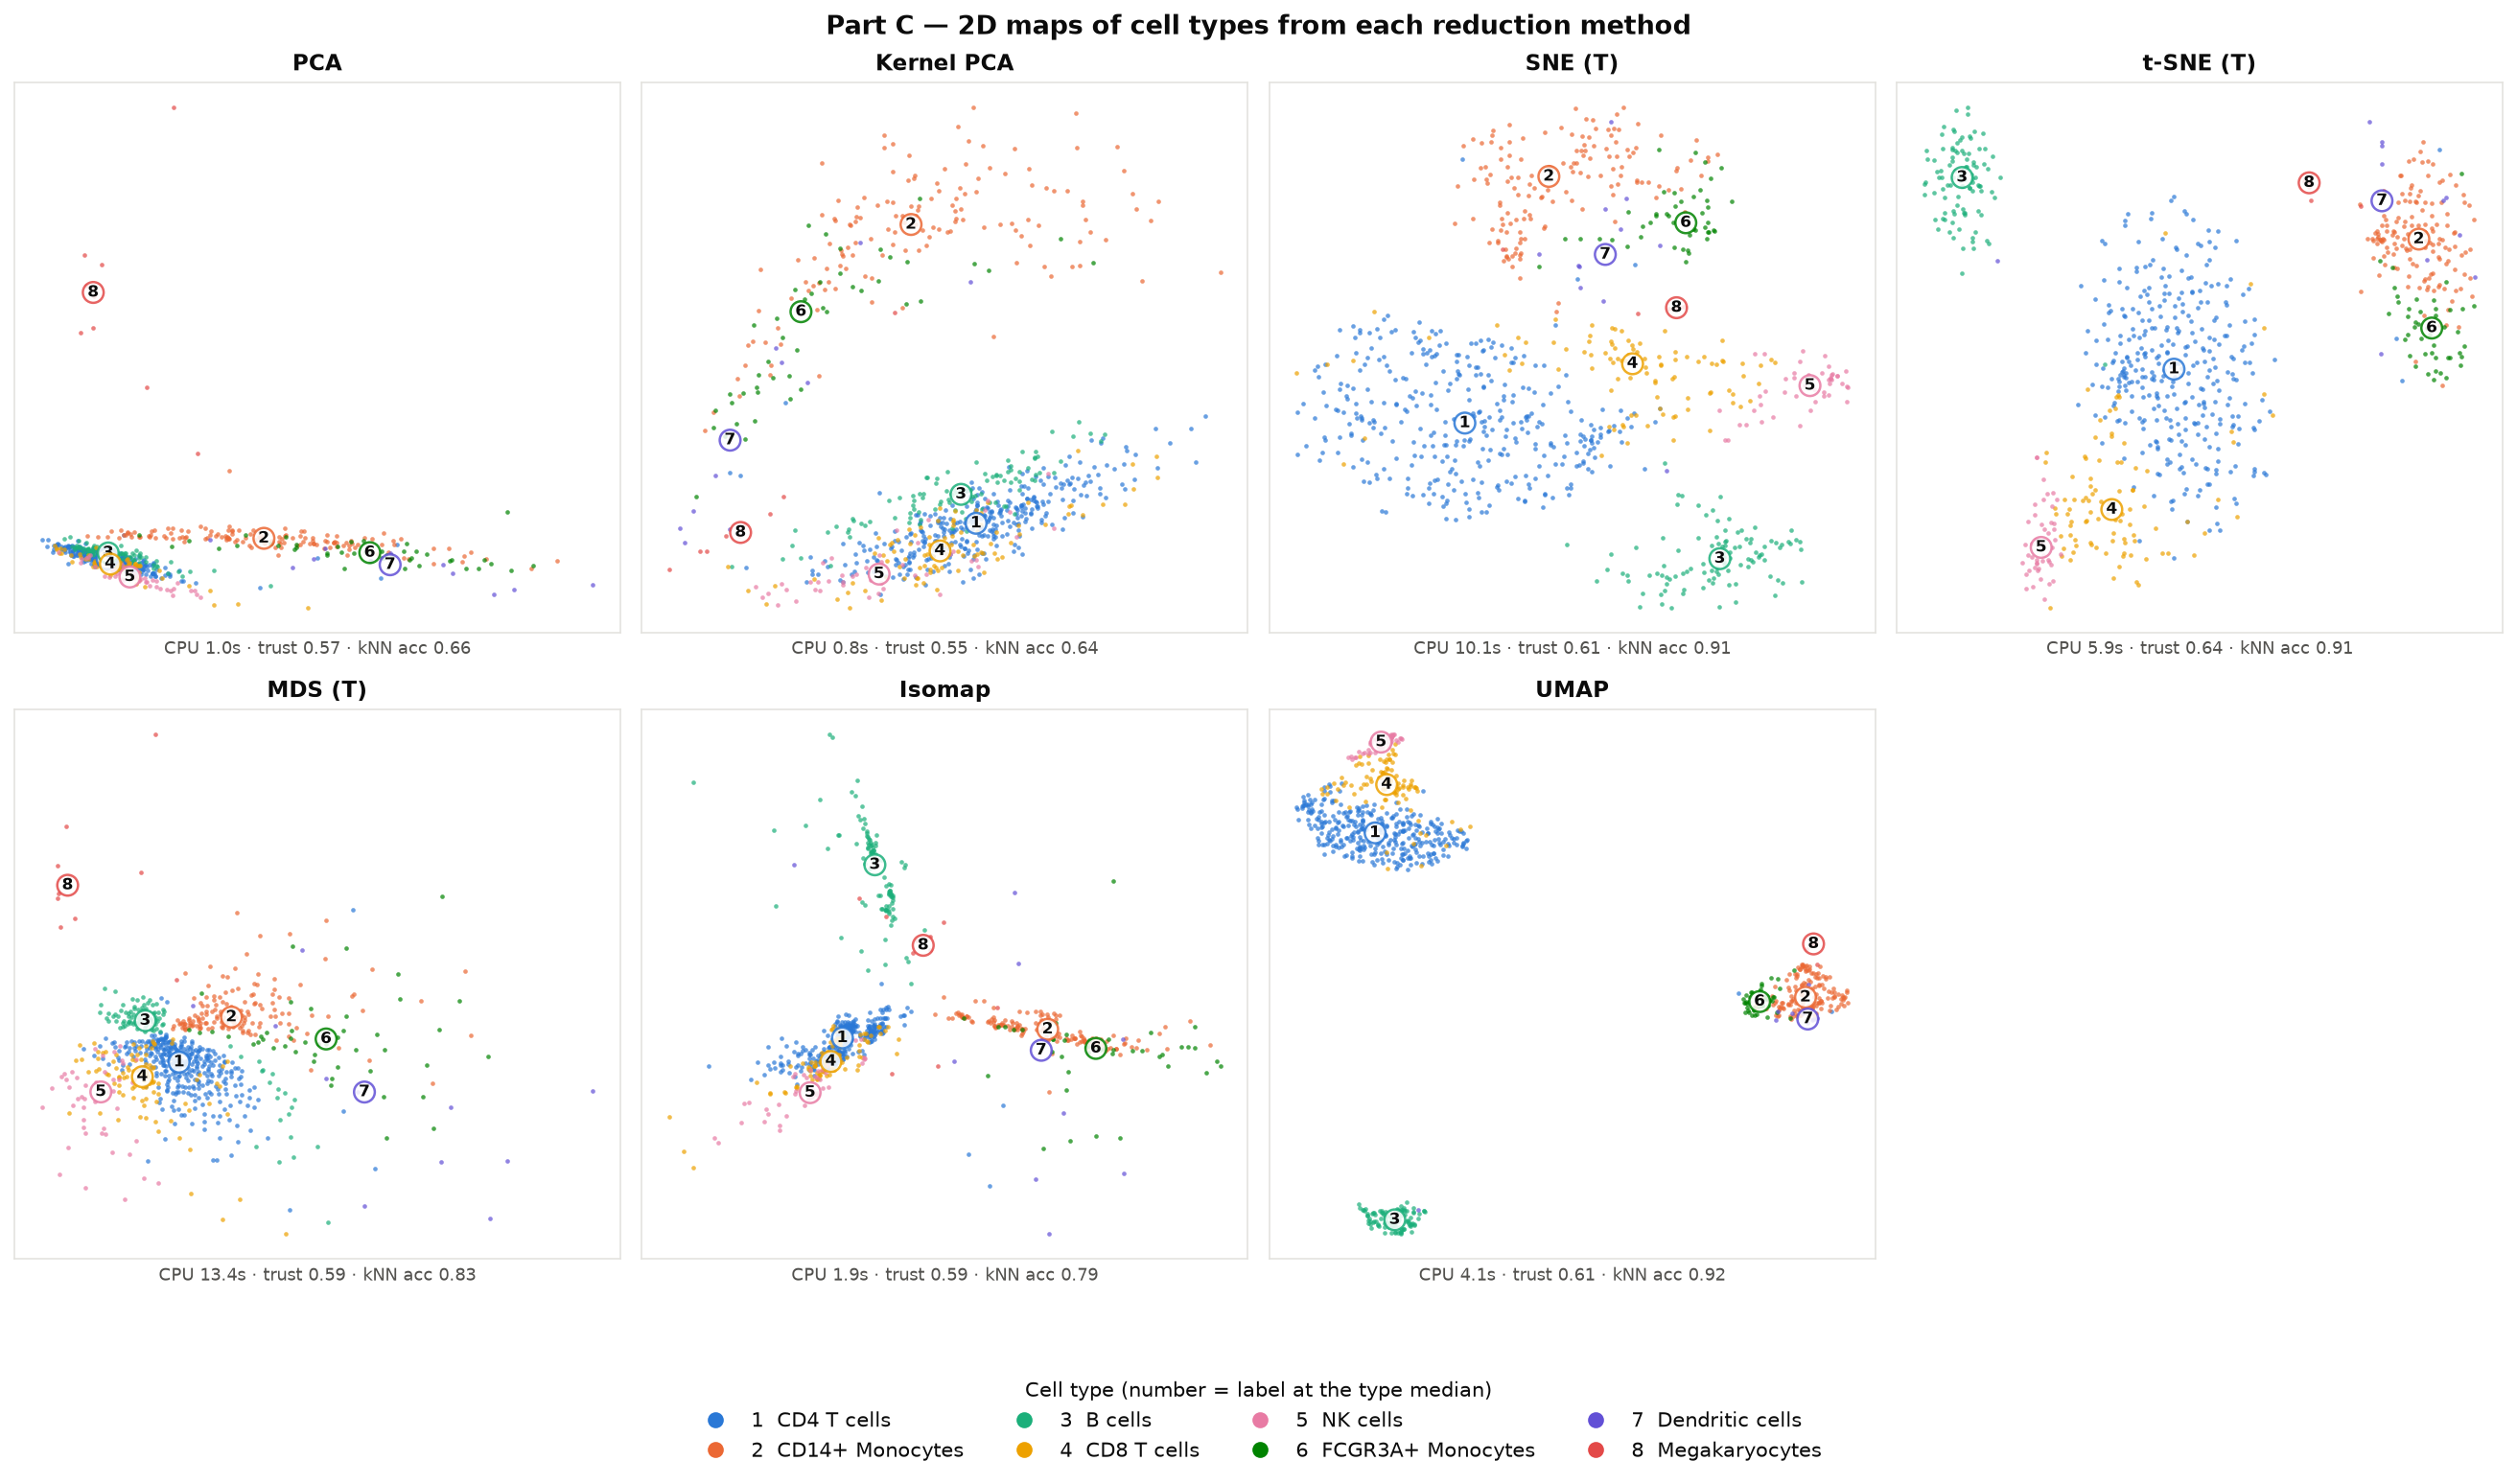

In [35]:
Cres = run_partC(ds, cfg, precomputed=EMB2D)
show('partC_2d_grid_dr.png')

**How to read this graph.** One panel per method, coloured by cell type (legend at the bottom). Look for: (1) **separation**: do types form distinct islands? (2) **mixing**: CD4 (1) vs CD8 (4) T cells and the two monocyte types (2, 6) are the hard pairs. (3) **outliers**: the 15 megakaryocytes (8) should form their own small group. t-SNE, SNE and UMAP separate the types most clearly (high kNN acc). PCA, Kernel PCA and MDS show the *global* arrangement (lymphoid vs myeloid along one axis) but overlap the subtypes. Isomap draws rays from a centre. **Remember:** in t-SNE/UMAP the distances *between* islands and their *sizes* carry little meaning.

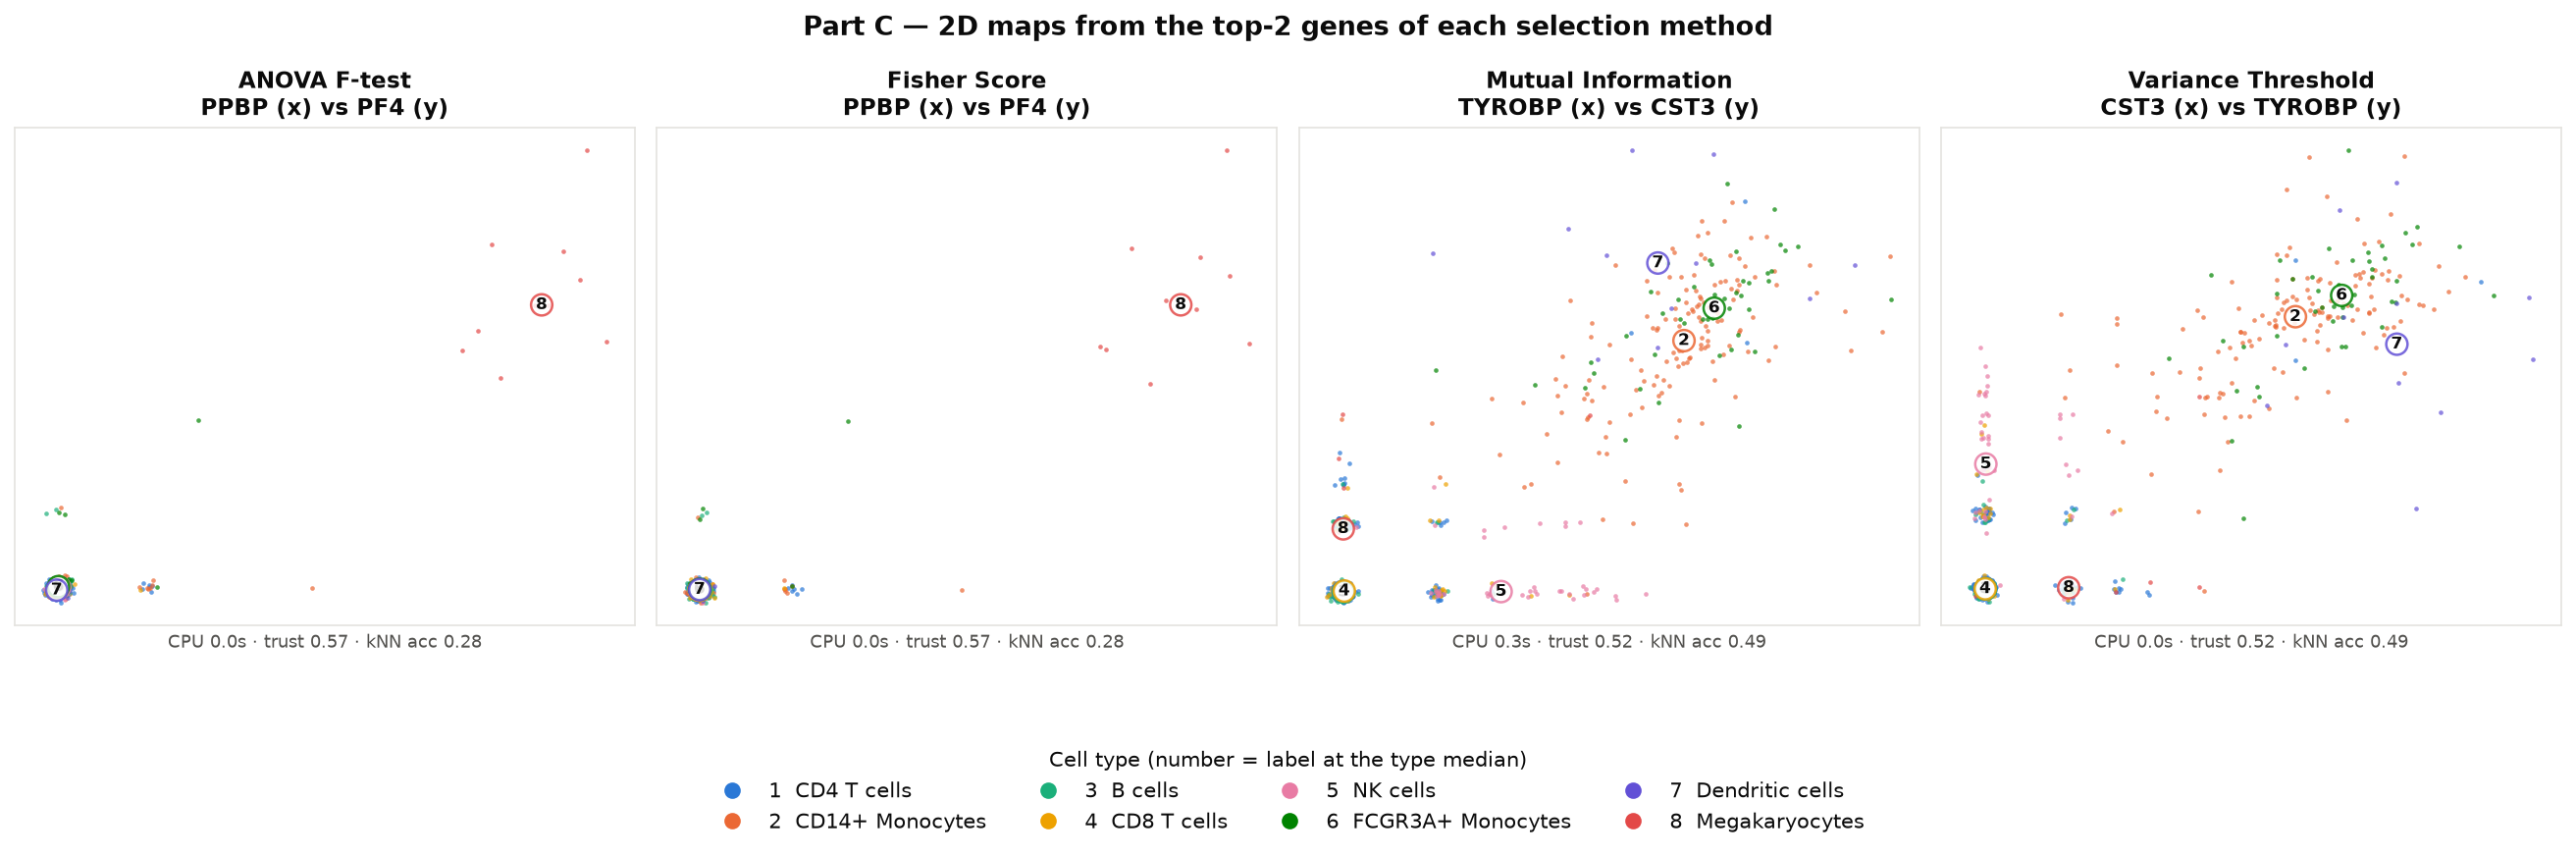

In [36]:
show('partC_2d_grid_fs.png')

**How to read this graph.** Each panel uses only the **two top-ranked genes** of a selection method as the x and y axes. These are real expression values, not a learned embedding, plus a tiny jitter so cells with identical values (many zeros) do not hide behind each other. Two genes can isolate one or two types (e.g. *PPBP* vs *PF4* isolates megakaryocytes perfectly, while everything else collapses at 0). That's why their kNN accuracy is far below the DR maps: **cell identity is a multi-gene program**, and you need tens of genes (Part B) or a DR method that mixes many genes (Part A) to separate all types.

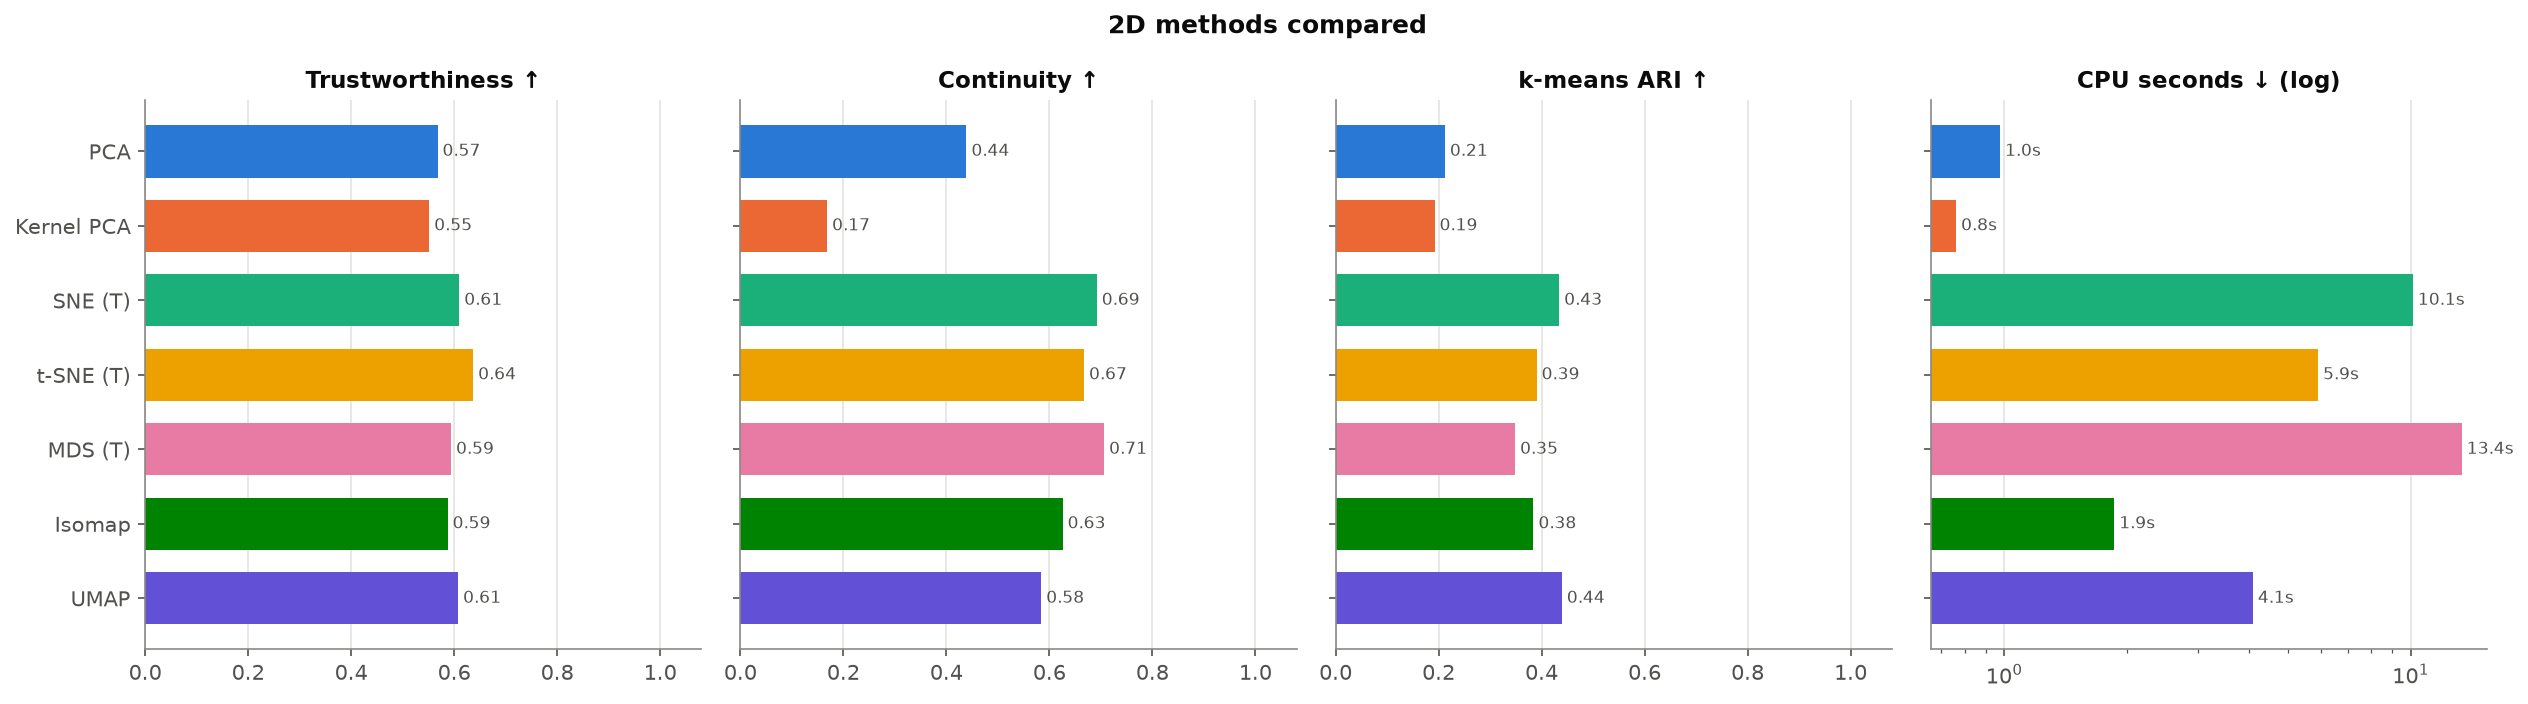

,method,kind,transductive,cpu_seconds,wall_seconds,trustworthiness,continuity,knn_preservation,ari,silhouette,knn_accuracy_2d
0,PCA,reduction,False,0.976,0.125,0.568,0.439,0.021,0.212,-0.027,0.659
1,Kernel PCA,reduction,False,0.761,0.097,0.551,0.168,0.013,0.192,-0.053,0.639
2,SNE,reduction,True,10.120,2.419,0.610,0.692,0.026,0.434,0.310,0.914
3,t-SNE,reduction,True,5.917,1.111,0.637,0.667,0.031,0.390,0.335,0.907
4,MDS,reduction,True,13.354,1.758,0.594,0.706,0.022,0.348,0.175,0.829
5,Isomap,reduction,False,1.865,0.305,0.587,0.626,0.019,0.384,0.128,0.789
6,UMAP,reduction,False,4.089,1.526,0.608,0.584,0.025,0.439,0.360,0.921
7,ANOVA F-test: PPBP vs PF4,selection,False,0.006,0.006,0.567,0.521,0.008,0.022,-0.880,0.280
8,Fisher Score: PPBP vs PF4,selection,False,0.005,0.005,0.567,0.521,0.008,0.022,-0.880,0.280
9,Mutual Information: TYROBP vs CST3,selection,False,0.290,4.130,0.521,0.582,0.009,0.294,-0.091,0.487


In [37]:
show('partC_2d_summary.png')
Cres['metrics']

**How to read this graph.** Four panels, one bar per 2D method. Trustworthiness and continuity (↑, 0–1) measure neighbourhood faithfulness in both directions. ARI (↑) measures whether k-means on the 2D map rediscovers the cell types. CPU seconds (↓, log scale) is the price. A good default is a method on the far right in the first three panels and on the left in the last. UMAP usually offers the best balance, and t-SNE is close but slower. PCA is near-instant but less faithful in 2D. MDS and SNE are expensive for what they deliver.

## 8. Which method should I use and when?

| Method | Linear? | Preserves | New data (`transform`)? | Speed (n ≈ 3k) | Typical use |
|---|---|---|---|---|---|
| **PCA** | linear | global variance | ✅ yes | ⚡ very fast | first step for everything; denoising; input to t-SNE/UMAP/clustering |
| **Kernel PCA** | nonlinear | kernel similarities | ✅ yes | fast–medium (O(n²) memory) | curved structure in small data; needs γ tuning |
| **MDS** | (nonlinear map) | all pairwise distances (global) | ❌ transductive | 🐢 slow (O(n²)) | small data where real distances matter (e.g. samples, not cells) |
| **Isomap** | nonlinear | geodesic (along-manifold) distances | ✅ yes | medium | one continuous manifold (trajectories), noise-free data |
| **SNE** | nonlinear | local neighbourhoods | ❌ transductive | 🐢 slow | teaching: understanding t-SNE |
| **t-SNE** | nonlinear | local neighbourhoods | ❌ transductive | medium (Barnes–Hut, ≤3D) | visualising clusters; never read inter-cluster distances |
| **UMAP** | nonlinear | local + some global | ✅ yes | fast | default 2D visualisation of scRNA-seq; also as features |
| **Variance** | – (selection) | high-variance genes | ✅ | ⚡ | unsupervised pre-filter (HVGs) |
| **ANOVA F / Fisher** | – (selection) | per-gene class separation | ✅ | ⚡ | quick supervised marker ranking |
| **Mutual information** | – (selection) | any per-gene dependency | ✅ | medium | nonlinear marker ranking |
| **Lasso (L1)** | – (selection) | jointly predictive, non-redundant genes | ✅ | slow-ish | compact marker panels covering all types |

**Rules of thumb**
* **Classification on a new batch of cells:** feature selection (interpretable, cheap) or PCA. Both have `transform`.
* **A 2D picture for a paper:** UMAP, or t-SNE. Run PCA-50 first, try a couple of perplexities / `n_neighbors`, and fix the seed.
* **Trajectories / continuous processes:** PCA, Isomap or diffusion maps. Avoid reading t-SNE distances.
* **Need biology you can validate in the lab:** feature selection (Lasso for compact panels, ANOVA/MI for rankings).

## 9. Common pitfalls

**1. Data leakage.** Anything learned from data (scaler means, PCA axes, selected genes) must be learned on the training fold only. The most damaging case is supervised feature selection on all cells. The demo below takes 100 cells and gives them **random labels** (50 "A", 50 "B"), so there is *nothing* to learn and the true accuracy is 50 %. It then compares a leaky protocol with an honest one:

In [38]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from src.selection import TopKSelector

rng = np.random.default_rng(SEED)
idx = rng.choice(len(ds.y), 100, replace=False)               # few cells, many genes: typical in genomics
X_small = ds.X[idx]
y_random = rng.permutation(np.r_[np.zeros(50, int), np.ones(50, int)])   # pure noise labels
cv5 = StratifiedKFold(5, shuffle=True, random_state=SEED)
knn = KNeighborsClassifier(**cfg['classifiers']['kNN'])

# LEAKY: pick the 20 genes that best match the random labels using ALL 100 cells, THEN cross-validate.
leaky_genes = top_k(gene_scores('ANOVA F-test', X_small, y_random, SEED)[0], 20)
leaky = cross_val_score(Pipeline([('scale', make_scaler(cfg)), ('clf', knn)]),
                        X_small[:, leaky_genes], y_random, cv=cv5).mean()
# HONEST: the selector lives inside the pipeline, so it is re-fit on each training fold.
honest = cross_val_score(Pipeline([('select', TopKSelector('ANOVA F-test', 20, SEED)),
                                   ('scale', make_scaler(cfg)), ('clf', knn)]),
                         X_small, y_random, cv=cv5).mean()
print(f'Random labels → leaky accuracy = {leaky:.2f}   honest accuracy = {honest:.2f}   (truth: 0.50)')

Random labels → leaky accuracy = 0.75   honest accuracy = 0.48   (truth: 0.50)


The leaky protocol reports a "signal" on pure noise. Out of 1,800 genes, some match the random labels by chance *on all 100 cells, including the test cells*, so the test folds have already been peeked at. The honest pipeline correctly stays near 50 %. On real data the same bias silently inflates every score, and it grows with more genes and fewer cells.

**2. Transductive embeddings.** t-SNE, SNE and MDS cannot place new cells, so their CV accuracies used test cells to build the embedding. Use them for *pictures*, not for deployable pipelines. If you need t-SNE-like features for new data, use UMAP (`transform`) or parametric t-SNE.

**3. t-SNE / UMAP distances are misleading.** Cluster sizes reflect density normalisation, not real size. Gaps between clusters are not proportional to biological difference, and an "island" may just be a perplexity artefact (see the perplexity sweep in §5.6). Validate any claim with the original genes.

**4. Hyperparameter sensitivity.** Perplexity (t-SNE/SNE), `n_neighbors` and `min_dist` (UMAP), `n_neighbors` (Isomap) and γ (Kernel PCA) all change the picture a lot (see the sweeps in §5). Always try a few values, and never tune them to make the picture "look like" what you expected.

**5. Preprocessing count data.** Without total-count normalisation, sequencing depth becomes the main axis of variation. Without `log1p`, a few highly expressed genes dominate. Scaling without clipping lets ultra-rare genes dominate PCA. Variance-based selection after scaling is meaningless (§2). Choosing highly variable genes reduces noise and computation.

**6. Class imbalance & label origin.** Accuracy hides failure on rare types, so report macro-F1. And remember the `louvain` labels came from clustering a PCA/kNN graph of this same data, which favours PCA/UMAP-like methods.

**7. Statistics on CV folds.** Folds overlap in training data, so paired tests are optimistic. With 5 folds, Wilcoxon cannot reach p < 0.05. Use repeated CV and treat p-values as rough guides.

## 10. Glossary

| Term | Meaning |
|---|---|
| **scRNA-seq** | Single-cell RNA sequencing: counts the RNA molecules of every gene in each individual cell. |
| **PBMC** | Peripheral blood mononuclear cells: lymphocytes (T, B, NK) and monocytes/dendritic cells from blood. |
| **Gene expression** | How actively a gene is used, measured as its RNA count. |
| **Highly variable genes (HVGs)** | Genes whose expression varies most across cells; usually the informative ones. |
| **Normalisation / log1p** | Rescaling each cell to the same total count, then `log(1+x)` to tame skew. |
| **Cell type / louvain** | The label we predict; *Louvain* is the graph-clustering algorithm that produced it. |
| **Dimensionality reduction** | Building a few new coordinates that summarise many features. |
| **Feature selection** | Keeping a subset of the original features (genes). |
| **Manifold** | A low-dimensional, possibly curved surface on which high-dimensional data approximately lies. |
| **Embedding** | The new low-dimensional coordinates assigned to each cell. |
| **Inductive / transductive** | Can embed new data with a learned mapping / can only embed the points it was given. |
| **Data leakage** | Information from test data influencing training, which makes results look better than they are. |
| **Curse of dimensionality** | In very many dimensions all distances become similar, and neighbourhoods lose meaning. |
| **Perplexity** | t-SNE/SNE's smooth measure of how many neighbours each point considers. |
| **Geodesic distance** | Distance measured along the manifold (through the neighbour graph), not straight through space. |
| **Trustworthiness** | 0–1. Are neighbours in the embedding true neighbours in the original space? Penalises false neighbours. |
| **Continuity** | 0–1. Are original neighbours kept as neighbours in the embedding? Penalises torn-apart neighbourhoods. |
| **k-NN preservation** | Fraction of each point's k nearest neighbours shared between the two spaces. |
| **ARI** | Adjusted Rand Index: agreement between two clusterings, corrected for chance (0 random, 1 identical). |
| **Silhouette** | −1 to 1. How much closer points are to their own group than to the nearest other group. |
| **Macro-F1** | F1 computed per class, then averaged, so every class counts equally. |
| **Cohen's κ** | Agreement corrected for chance. |
| **ROC AUC (one-vs-rest)** | Probability that a random cell of type c gets a higher "type c" score than a random other cell, averaged over types. |
| **CPU time** | Processor time consumed by the program, summed over threads (`time.process_time`). |
| **Wall time** | Elapsed real time (`time.perf_counter`). |
| **Stratified CV** | Cross-validation whose folds keep the class proportions. |
| **Paired test** | A test comparing two methods on the same folds (t-test, Wilcoxon). |
| **Jaccard similarity** | Overlap of two sets: intersection ÷ union. |
| **Bootstrap** | Resampling the data with replacement to measure variability. |

---
All tables are in `outputs/tables/` and all figures in `outputs/figures/` (see `README.md` for a file-by-file description).